# 07 — Comprehensive 2μ2e summary: MC SR candidates and validation regions

This notebook preserves the original **five-WP intermediate-mass summary and all eight figures** below, then adds the research-group follow-up studies.

- **Part I (original):** nominal MC-ranked candidates; 150≤MJJ<300 GeV PP/PD/DP validation. The original block's cached-only scope and provenance apply to that block.
- **Part II:** decompose the maximum S/B into ABCD regions, fixed signal hypotheses and direct background MC yields.
- **Part III:** test nominal DD MC signal retention, background composition, closure and statistical support.
- **Part IV:** audit nominal B/C/D contamination and overlap with protected A regions before any DATA access.
- **Part V:** repeat the closure tests in PP/PD/DP with no physical mass upper cut, including <150 and ≥300 GeV contributions.

**Nominal DATA A remains blind. No nominal DATA yields are read or inferred.** The follow-up block reads original MC and only contamination-approved, disjoint PP/PD/DP VR DATA. PP and PD are the primary tests; DP remains auxiliary.

The five candidates and the original reference are not re-ranked using these follow-up DATA plots. WP1=(0.20,2.6) and WP2=(0.20,2.7) remain the leading alternatives under discussion.


# 07 — Intermediate MJJ VR working-point comparison (2μ2e)

**Scope:** **Intermediate MJJ VR: 150 ≤ MJJ < 300 GeV**, with
**0≤partner isolation<0.5**. Evaluate **PP and PD together** and show the
same selected WPs in **PP, PD, and DP**, in that order throughout.

The notebook starts with a **comprehensive five-WP summary table**, followed by
**eight comparison figures**: significance, two annotated full-range κ maps,
joint PP–PD closure, selected-WP yields/closure/contamination, and three 1D stability scans.
Detailed comparisons contain **only five WPs**.

The candidates are the **five highest nominal-SR MC significance ratios** in
the native local grid: iso={0.20,0.25,0.30,0.40}, |Δφ|={2.4,2.6,2.7,2.8}.
The reference (0.30,2.6) defines the significance normalization; it is shown as
a selected WP only if it belongs to the top five. It is not forced into the list.
PP/PD DATA closure is evaluated after this MC-only selection. DP does not select candidates.

**Nominal DATA is never accessed.** This focused version reads only the
validated notebook-03 tables; it does not reopen raw MC, signal, or DATA files.
Use **Restart → Run All** to reproduce the notebook.


In [1]:
from pathlib import Path
import sys

SIDM_DIR = next((p for p in (Path.cwd(), *Path.cwd().parents) if p.name == 'sidm'), None)
if SIDM_DIR is None:
    raise RuntimeError('Run this notebook from inside the sidm repository.')
NOTEBOOK_DIR = SIDM_DIR / 'studies' / 'ABCD_finalize'
for folder in (SIDM_DIR.parent, NOTEBOOK_DIR):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import coffea.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from abcd_finalize_common import finalize_local_scan_build_vr2_focus_config as build_vr2_focus_config, finalize_local_scan_run_vr2_focus as run_vr2_focus, finalize_local_scan_vr2_focus_summary_tables as vr2_focus_summary_tables
from abcd_finalize_plots import finalize_local_scan_plots_make_vr2_focus_figures as make_vr2_focus_figures, finalize_local_scan_plots_vr2_focus_figure_definitions as vr2_focus_figure_definitions

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 100, 'font.size': 11, 'figure.max_open_warning': 0})
CONFIG = build_vr2_focus_config(NOTEBOOK_DIR, selection_mode='sr_significance', force_reference=False)
CONFIG.update(scan_iso_limits=(0., 1.), scan_dphi_limits=(1., 3.))
OUTPUT_DIR = Path(CONFIG['output_dir'])


## 1. Comprehensive summary of the five selected WPs

For each of the **60 matching 2Mu2E signal hypotheses**, compute the known-background
Asimov $Z_A$ from the nominal DD MC SR A yields and divide by its value at (0.30,2.6).
Rank the local WPs by the median of those **per-hypothesis ratios**.
Production normalization and the existing ABCD definitions are unchanged.
Different signal hypotheses are not summed.

**A=low iso/high |Δφ|**, B=high/high, C=low/low, D=high/low.
The reference enters the normalization even when it is outside the displayed top five.
The five-row table contains SR signal/background yields, effective counts, κ and significance,
plus DATA A/B/C/D, BC/D, DATA/MC κ, contamination and statistical support in PP, PD and DP.
SR MC is the nominal DD selection used for ranking; PP/PD/DP are the Intermediate MJJ VR (150 ≤ MJJ < 300 GeV).
Signal yield and Z medians use the 60 matching hypotheses; ranges in brackets are
the **10th–90th model percentiles**, not statistical confidence intervals.
The DATA contamination gate still requires $S/B_{MC}<0.10$ in every ABCD region
for **all 120 distinct signal hypotheses**. Gate approval is not a closure-quality test.


In [2]:
results = run_vr2_focus(CONFIG)
tables = results['tables']
selected = tables['working_points'].sort_values('rank')
ranked = tables['ranking'].set_index('wp')
summary_tables = vr2_focus_summary_tables(results)
selected_table = summary_tables['display']
summary_numeric = summary_tables['numeric']

from html import escape
from IPython.display import HTML

summary_palette = ('#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00')
summary_css = """
<style>
#sidm-wp-summary {font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", sans-serif;
  color: #1e293b; max-width: 100%; margin: 8px 0 16px;}
#sidm-wp-summary .summary-heading {display: flex; align-items: center; justify-content: space-between;
  gap: 12px; margin: 0 0 10px;}
#sidm-wp-summary .summary-heading strong {font-size: 17px; letter-spacing: -.2px;}
#sidm-wp-summary .summary-count {border: 1px solid #dbe4ee; border-radius: 99px;
  padding: 4px 10px; color: #64748b; font-size: 11px; white-space: nowrap;}
#sidm-wp-summary .summary-scroll {overflow-x: auto; border: 1px solid #dce4ee;
  border-radius: 12px; box-shadow: 0 3px 12px rgba(15, 23, 42, .045);}
#sidm-wp-summary table {border-collapse: separate; border-spacing: 0; width: 100%;
  min-width: 1060px; margin: 0; font-size: 11.5px; line-height: 1.4;}
#sidm-wp-summary th {background: #17263b; color: #f8fafc; text-align: left;
  padding: 12px 14px 10px; border-top: 3px solid #64748b; border-left: 1px solid #304155;
  font-size: 12px; font-weight: 650; white-space: nowrap;}
#sidm-wp-summary th:first-child {text-align: center; border-left: none;}
#sidm-wp-summary th:nth-child(2) {border-top-color: #38a3cf;}
#sidm-wp-summary th:nth-child(3) {border-top-color: #37b6a3;}
#sidm-wp-summary th:nth-child(4) {border-top-color: #ad8bd1;}
#sidm-wp-summary th:nth-child(5) {border-top-color: #e9b75c;}
#sidm-wp-summary .header-note {display: block; margin-top: 3px; color: #bdcbdc;
  font-size: 10px; font-weight: 400;}
#sidm-wp-summary td {background: #fff; vertical-align: top; padding: 11px 12px;
  border-top: 1px solid #e6ebf2; border-left: 1px solid #e6ebf2; min-width: 220px;}
#sidm-wp-summary tbody tr:nth-child(even) td {background: #f7f9fc;}
#sidm-wp-summary tbody tr:first-child td {border-top: none;}
#sidm-wp-summary td.wp-cell {min-width: 82px; width: 88px; padding: 12px 8px;
  border-left: none; vertical-align: middle; text-align: center;}
#sidm-wp-summary .wp-badge {display: inline-block; color: white; font-size: 13px;
  font-weight: 700; border-radius: 7px; padding: 5px 10px; margin-bottom: 7px;}
#sidm-wp-summary .cut-chip {display: block; color: #475569; font-size: 10.5px;
  white-space: nowrap; font-variant-numeric: tabular-nums; margin: 4px 0;}
#sidm-wp-summary .metric-row {display: flex; justify-content: space-between;
  align-items: baseline; column-gap: 9px; margin: 0 0 6px;}
#sidm-wp-summary .metric-row:last-child {margin-bottom: 0;}
#sidm-wp-summary .metric-label {color: #64748b; font-size: 10.5px; flex: 0 1 auto;}
#sidm-wp-summary .metric-value {color: #243449; text-align: right; font-weight: 550;
  white-space: nowrap; font-variant-numeric: tabular-nums; font-feature-settings: "tnum";}
#sidm-wp-summary .primary-metric {padding-top: 5px; margin-top: 4px;
  border-top: 1px solid #dfe7f0;}
#sidm-wp-summary .primary-metric .metric-label {color: #075985; font-weight: 650;}
#sidm-wp-summary .primary-metric .metric-value {color: #075985; font-weight: 750;}
#sidm-wp-summary .gate-tag {display: inline-block; border: 1px solid #d3deea;
  border-radius: 4px; padding: 0 4px; margin-left: 3px; background: #edf3f9;
  color: #36566f; font-size: 9.5px; font-weight: 600;}
#sidm-wp-summary .summary-note {font-size: 10.5px; line-height: 1.5; color: #64748b;
  margin: 9px 2px 0;}
</style>
"""
summary_notes = ('Selected cuts', '60 matching signal models',
                 '150 ≤ MJJ < 300 GeV · DATA / MC', '150 ≤ MJJ < 300 GeV · DATA / MC',
                 '150 ≤ MJJ < 300 GeV · DATA / MC')
summary_headers = ''.join(
    '<th>' + escape(str(name)) + '<span class="header-note">' + escape(note) + '</span></th>'
    for name, note in zip(selected_table.columns, summary_notes))
summary_body_rows = []
for summary_index, summary_row in selected_table.iterrows():
    summary_cells = []
    for summary_column, summary_value in enumerate(summary_row):
        summary_lines = str(summary_value).splitlines()
        if summary_column == 0:
            summary_content = ('<span class="wp-badge" style="background:'
                               + summary_palette[summary_index % len(summary_palette)] + '">'
                               + escape(summary_lines[0]) + '</span>')
            summary_content += ''.join('<span class="cut-chip">' + escape(line) + '</span>'
                                       for line in summary_lines[1:])
            summary_cells.append('<td class="wp-cell">' + summary_content + '</td>')
            continue
        summary_items = []
        for summary_line in summary_lines:
            summary_label, summary_separator, summary_number = summary_line.partition(':')
            if not summary_separator:
                summary_items.append('<div class="metric-row">' + escape(summary_line) + '</div>')
                continue
            summary_number_html = escape(summary_number.strip())
            if ' | gate: ' in summary_number:
                summary_amount, summary_gate = summary_number.strip().split(' | gate: ', 1)
                summary_number_html = (escape(summary_amount) + ' | <span class="gate-tag">gate: '
                                       + escape(summary_gate) + '</span>')
            summary_class = 'metric-row primary-metric' if summary_label == 'Z/ref' else 'metric-row'
            summary_items.append('<div class="' + summary_class + '"><span class="metric-label">'
                                 + escape(summary_label) + ':</span><span class="metric-value">'
                                 + summary_number_html + '</span></div>')
        summary_cells.append('<td>' + ''.join(summary_items) + '</td>')
    summary_body_rows.append('<tr>' + ''.join(summary_cells) + '</tr>')
summary_html = (summary_css + '<div id="sidm-wp-summary"><div class="summary-heading">'
                '<strong>Selected working points</strong><span class="summary-count">'
                + str(len(selected_table)) + ' WPs · Intermediate MJJ VR (150 ≤ MJJ &lt; 300 GeV)</span></div>'
                '<div class="summary-scroll"><table><thead><tr>' + summary_headers
                + '</tr></thead><tbody>' + ''.join(summary_body_rows) + '</tbody></table></div>'
                '<div class="summary-note">SR signal and significance medians use 60 matching hypotheses; '
                'bracketed ranges show model 10–90% percentiles. Contamination maxima use all 120 hypotheses. '
                'Gate PASS means the contamination criterion is satisfied; it does not establish closure.</div></div>')
display(HTML(summary_html))
print('Selected WPs:', len(selected), '| Reference selected:', bool(selected.is_reference.any()))


WP / cutsSelected cuts,Nominal SR MC60 matching signal models,PP150 ≤ MJJ < 300 GeV · DATA / MC,PD150 ≤ MJJ < 300 GeV · DATA / MC,DP150 ≤ MJJ < 300 GeV · DATA / MC
WP1iso = 0.20|Δφ| = 2.6,"S(A), model median:0.7062B(A):2.265 ± 1.150N_eff(A):3.88; min CR: 1.96κ:0.064 ± 0.074Z, model median:0.44755Z/ref:3.156 [2.288, 3.300]MC-stat diagnostic Z/ref:6.808","DATA A/B/C/D:460/1036/185/471BC/D:406.9 ± 37.5κ DATA:1.130 ± 0.117κ MC:0.561 ± 0.385max S/B:0.210% | gate: PASSmin DATA:185; MC N_eff,min: 5.13","DATA A/B/C/D:866/999/356/524BC/D:678.7 ± 51.3κ DATA:1.276 ± 0.106κ MC:0.410 ± 0.260max S/B:0.215% | gate: PASSmin DATA:356; MC N_eff,min: 6.02","DATA A/B/C/D:23/44/14/23BC/D:26.8 ± 9.9κ DATA:0.859 ± 0.365κ MC:1.153 ± 1.728max S/B:2.114% | gate: PASSmin DATA:14; MC N_eff,min: 1.00"
WP2iso = 0.20|Δφ| = 2.7,"S(A), model median:0.6911B(A):2.162 ± 1.146N_eff(A):3.56; min CR: 1.76κ:0.074 ± 0.088Z, model median:0.44776Z/ref:3.117 [2.273, 3.306]MC-stat diagnostic Z/ref:6.687","DATA A/B/C/D:420/952/225/555BC/D:385.9 ± 33.0κ DATA:1.088 ± 0.107κ MC:0.783 ± 0.531max S/B:0.209% | gate: PASSmin DATA:225; MC N_eff,min: 4.81","DATA A/B/C/D:789/890/433/633BC/D:608.8 ± 43.1κ DATA:1.296 ± 0.103κ MC:0.474 ± 0.302max S/B:0.218% | gate: PASSmin DATA:433; MC N_eff,min: 6.52","DATA A/B/C/D:22/40/15/27BC/D:22.2 ± 8.0κ DATA:0.990 ± 0.413κ MC:1.540 ± 2.309max S/B:2.215% | gate: PASSmin DATA:15; MC N_eff,min: 1.00"
WP3iso = 0.20|Δφ| = 2.8,"S(A), model median:0.6674B(A):2.133 ± 1.146N_eff(A):3.47; min CR: 1.54κ:0.091 ± 0.110Z, model median:0.43575Z/ref:2.968 [2.206, 3.217]MC-stat diagnostic Z/ref:6.349","DATA A/B/C/D:358/820/287/687BC/D:342.6 ± 26.9κ DATA:1.045 ± 0.099κ MC:0.746 ± 0.504max S/B:0.212% | gate: PASSmin DATA:287; MC N_eff,min: 4.21","DATA A/B/C/D:680/755/542/768BC/D:532.8 ± 35.6κ DATA:1.276 ± 0.098κ MC:0.585 ± 0.378max S/B:0.223% | gate: PASSmin DATA:542; MC N_eff,min: 6.24","DATA A/B/C/D:20/33/17/34BC/D:16.5 ± 5.7κ DATA:1.212 ± 0.498κ MC:1.722 ± 2.584max S/B:2.517% | gate: PASSmin DATA:17; MC N_eff,min: 1.00"
WP4iso = 0.20|Δφ| = 2.4,"S(A), model median:0.7214B(A):2.961 ± 1.325N_eff(A):4.99; min CR: 1.93κ:0.052 ± 0.059Z, model median:0.40371Z/ref:2.848 [2.175, 2.957]MC-stat diagnostic Z/ref:6.163","DATA A/B/C/D:512/1178/133/329BC/D:476.2 ± 50.9κ DATA:1.075 ± 0.124κ MC:1.580 ± 0.879max S/B:0.152% | gate: PASSmin DATA:133; MC N_eff,min: 7.91","DATA A/B/C/D:971/1144/251/379BC/D:757.6 ± 65.6κ DATA:1.282 ± 0.118κ MC:0.488 ± 0.312max S/B:0.211% | gate: PASSmin DATA:251; MC N_eff,min: 5.01","DATA A/B/C/D:26/49/11/18BC/D:29.9 ± 12.2κ DATA:0.868 ± 0.393κ MC:1.084 ± 1.626max S/B:1.901% | gate: PASSmin DATA:11; MC N_eff,min: 1.00"
WP5iso = 0.30|Δφ| = 2.7,"S(A), model median:0.6946B(A):16.829 ± 10.426N_eff(A):2.61; min CR: 1.46κ:0.133 ± 0.155Z, model median:0.16817Z/ref:1.174 [1.149, 1.197]MC-stat diagnostic Z/ref:1.177","DATA A/B/C/D:555/817/311/469BC/D:541.8 ± 43.9κ DATA:1.024 ± 0.094κ MC:1.043 ± 0.615max S/B:0.150% | gate: PASSmin DATA:311; MC N_eff,min: 7.35","DATA A/B/C/D:951/728/531/535BC/D:722.6 ± 51.7κ DATA:1.316 ± 0.103κ MC:0.423 ± 0.251max S/B:0.180% | gate: PASSmin DATA:531; MC N_eff,min: 8.14","DATA A/B/C/D:28/34/17/25BC/D:23.1 ± 8.3κ DATA:1.211 ± 0.490κ MC:1.537 ± 2.303max S/B:2.211% | gate: PASSmin DATA:17; MC N_eff,min: 1.00"


Selected WPs: 5 | Reference selected: False


## 2. Significance comparison

The three panels compare the same five WPs using

$$\frac{S}{\sqrt{B}},\qquad \frac{S}{\sqrt{S+B}},\qquad
Z_A=\sqrt{2[(S+B)\ln(1+S/B)-S]}.$$

S and B are the signal and background MC yields in nominal SR A, with unchanged
production normalization. Each metric is evaluated separately for the same
**60 matching signal hypotheses**, then summarized by its median and 10–90% model range.
All panels use a **shared log y-axis and the same bounds** for direct comparison.
The ranges describe signal-model variation, not statistical uncertainties or confidence intervals.

Only the selected five WPs are shown. Their original selection order is retained;
this figure compares absolute metrics and does not re-rank the candidates.


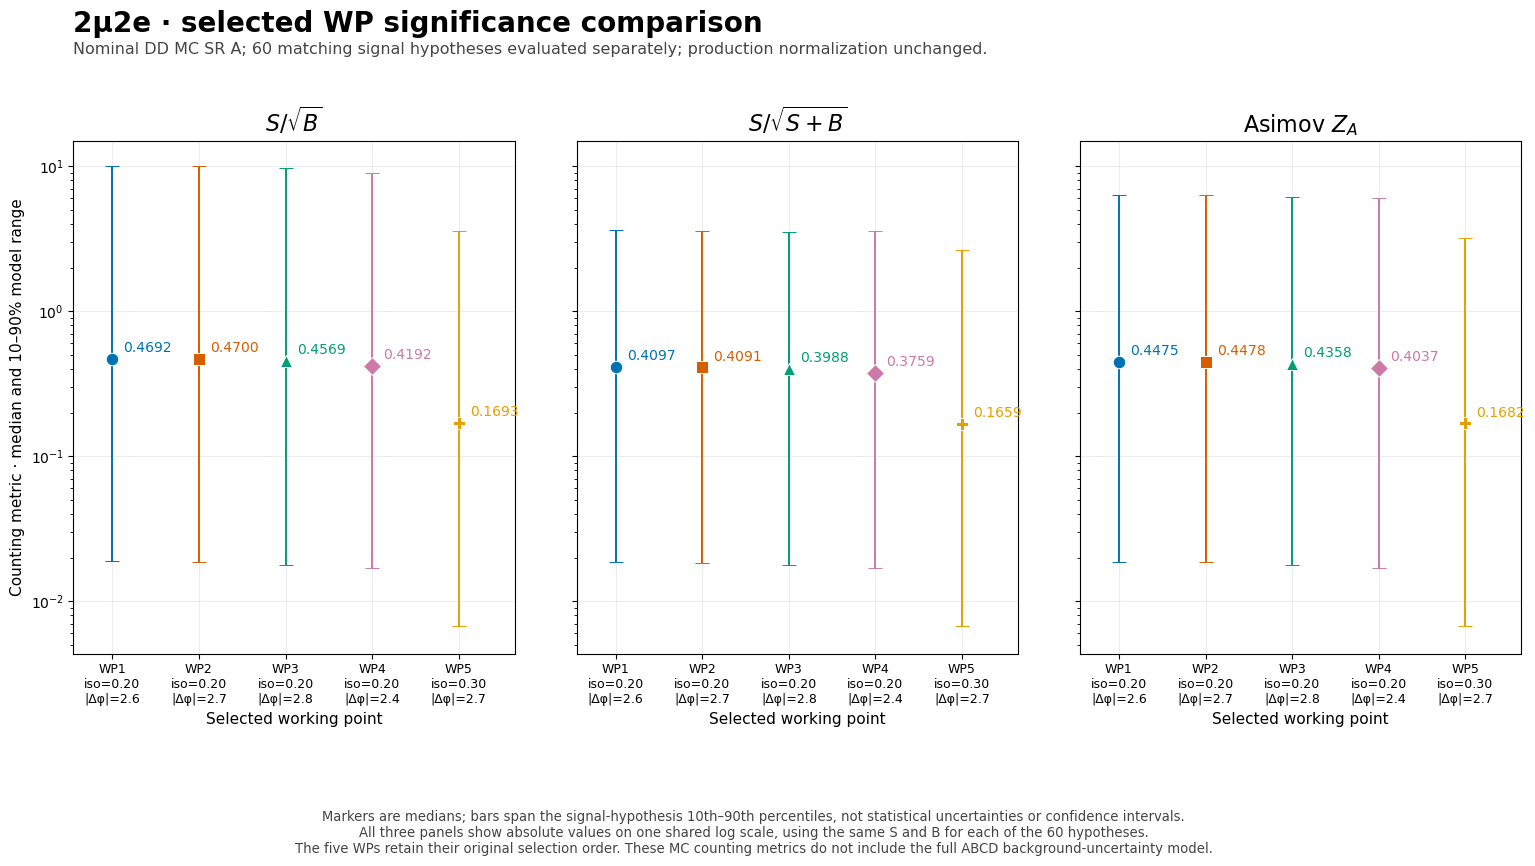

In [3]:
figure_definitions = vr2_focus_figure_definitions()
figures = make_vr2_focus_figures(results, CONFIG)
figure_lookup = {name: figure for figure, name in figures}
assert len(figures) == len(figure_lookup) == 8
for figure, _ in figures:
    plt.close(figure)
display(figure_lookup['significance_comparison'])


## 3.1. DATA: annotated full κ scan

All 154 native threshold points are shown as equal-spaced cells, as in notebooks 01–06. Tick labels give the actual isolation and angle thresholds through iso=2 and |Δφ|=π; zero splits are excluded. Each valid cell is labeled by its κ value. The violet rectangle encloses iso 0.20–0.40 and |Δφ| 2.4–2.8. DATA gates remain masked; there are no selected-WP markers.


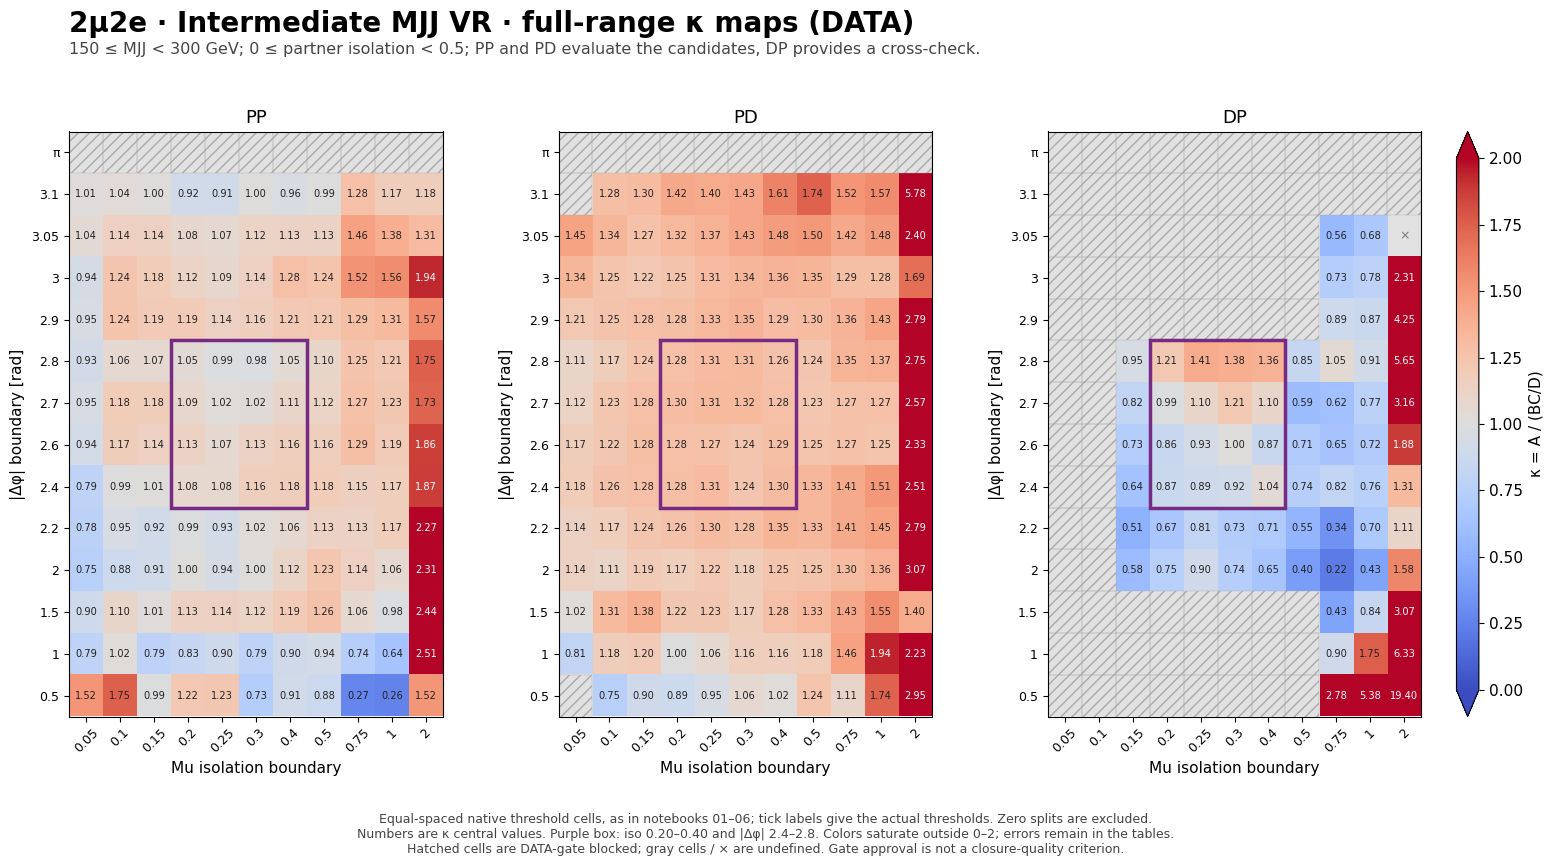

In [4]:
display(figure_lookup['full_data_kappa'])


## 3.2. MC: the same annotated full κ scan

The same threshold-grid display and local rectangle are used for MC. Colors share a κ=1 center and saturate outside 0–2. Numerical labels retain central values outside that range; uncertainties and support flags remain in the front summary and exported table.


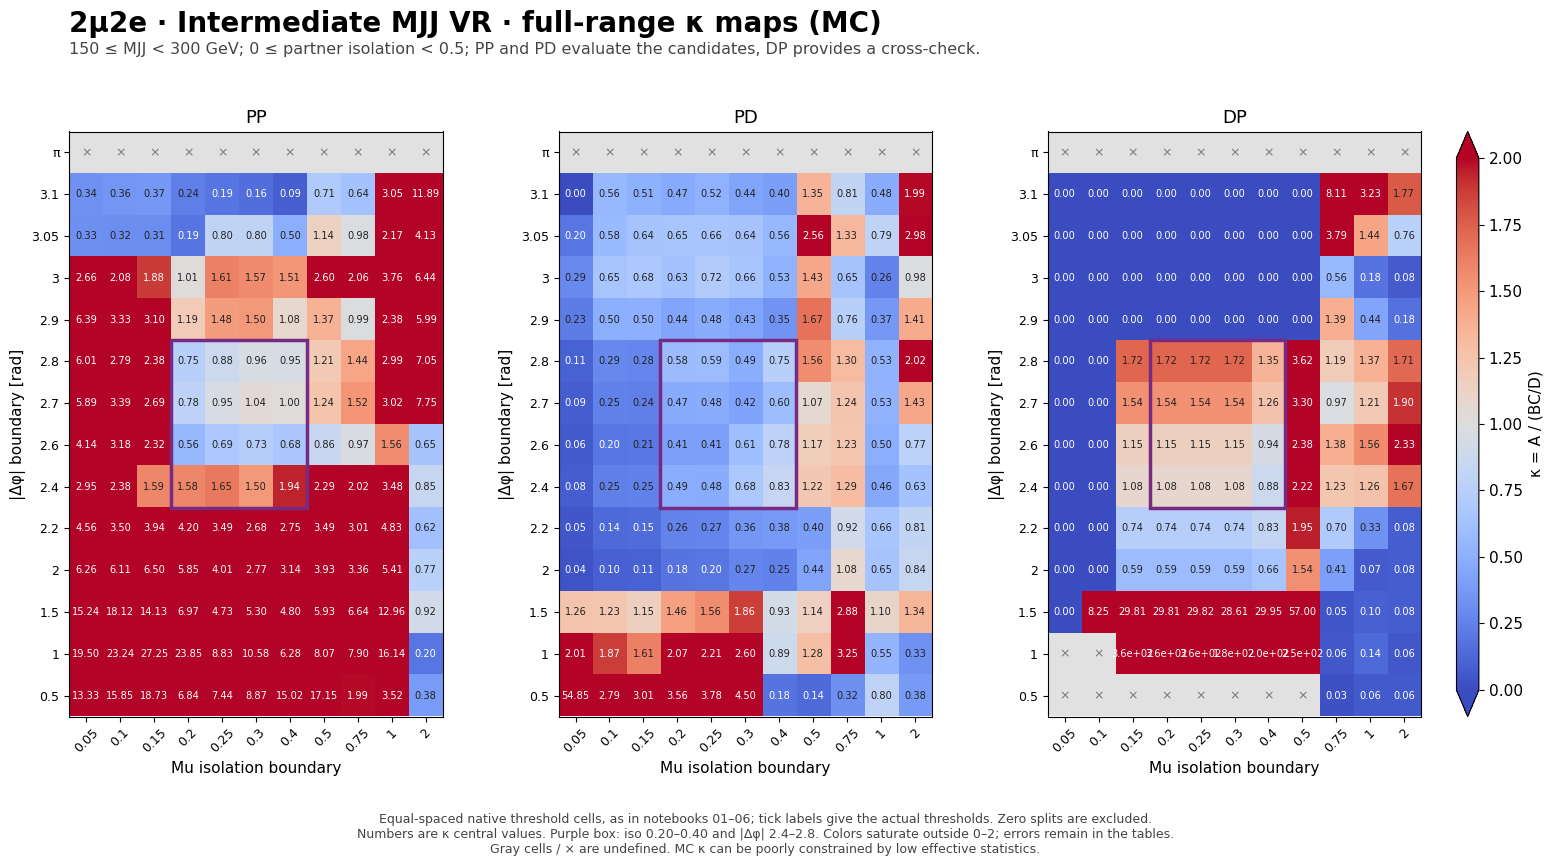

In [5]:
display(figure_lookup['full_mc_kappa'])


## 4. PP and PD evaluated together

Each marker is one selected WP: x is PP DATA κ and y is PD DATA κ, with marginal propagated errors. The (1,1) reference tests closure in both categories. Nearby WPs share events; this view does not define a new fit probability or selection score.


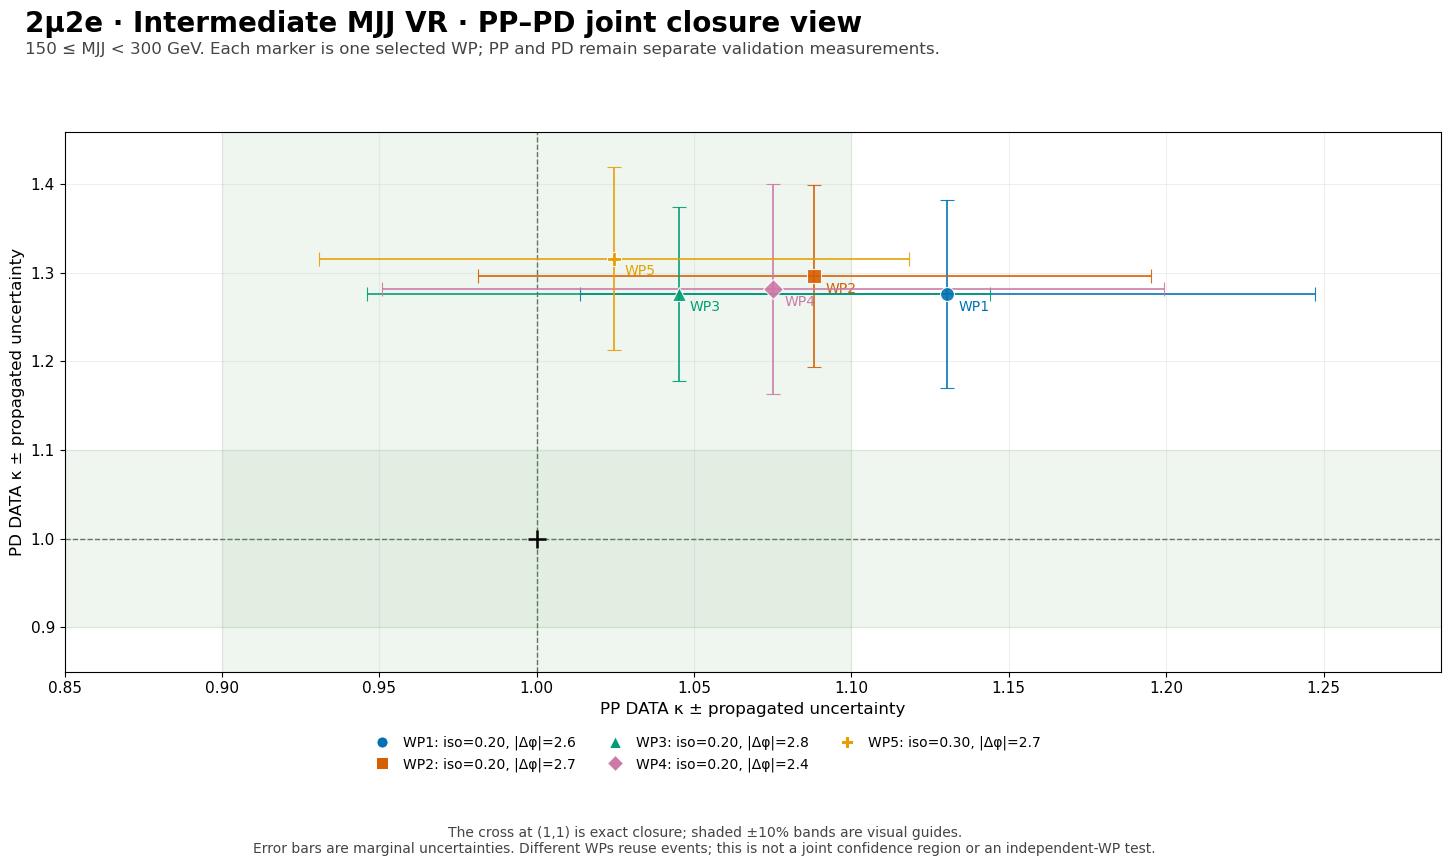

In [6]:
display(figure_lookup['pp_pd_joint'])


## 5. The five selected WPs in PP, PD, and DP

Columns are PP, PD, and DP. Rows show A and BC/D with uncertainties, κ with uncertainties, and the maximum MC S/B over all 120 hypotheses and ABCD regions. Only the selected five appear on the horizontal axes.


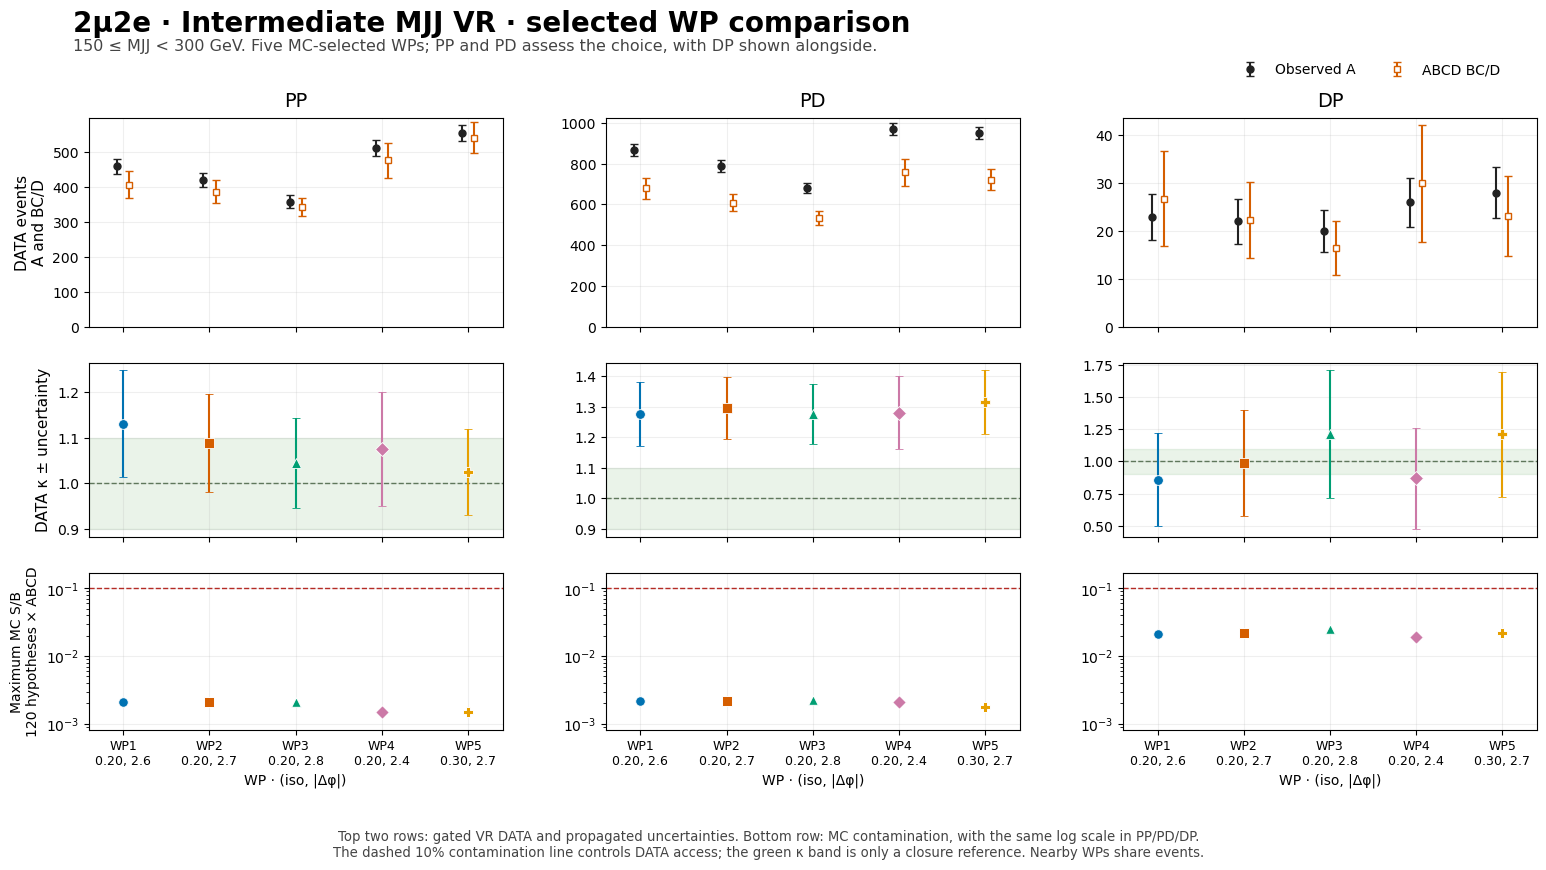

In [7]:
display(figure_lookup['selected_summary'])


## 6. PP: 1D stability comparisons

Display iso 0–1 and |Δφ| 1–3 using only the stored positive native thresholds. Columns scan isolation and angle; rows show yields, κ and contamination. The opposite coordinate is held fixed to a selected WP value. Shared curves are drawn once, and legends occupy dedicated areas outside the panels.


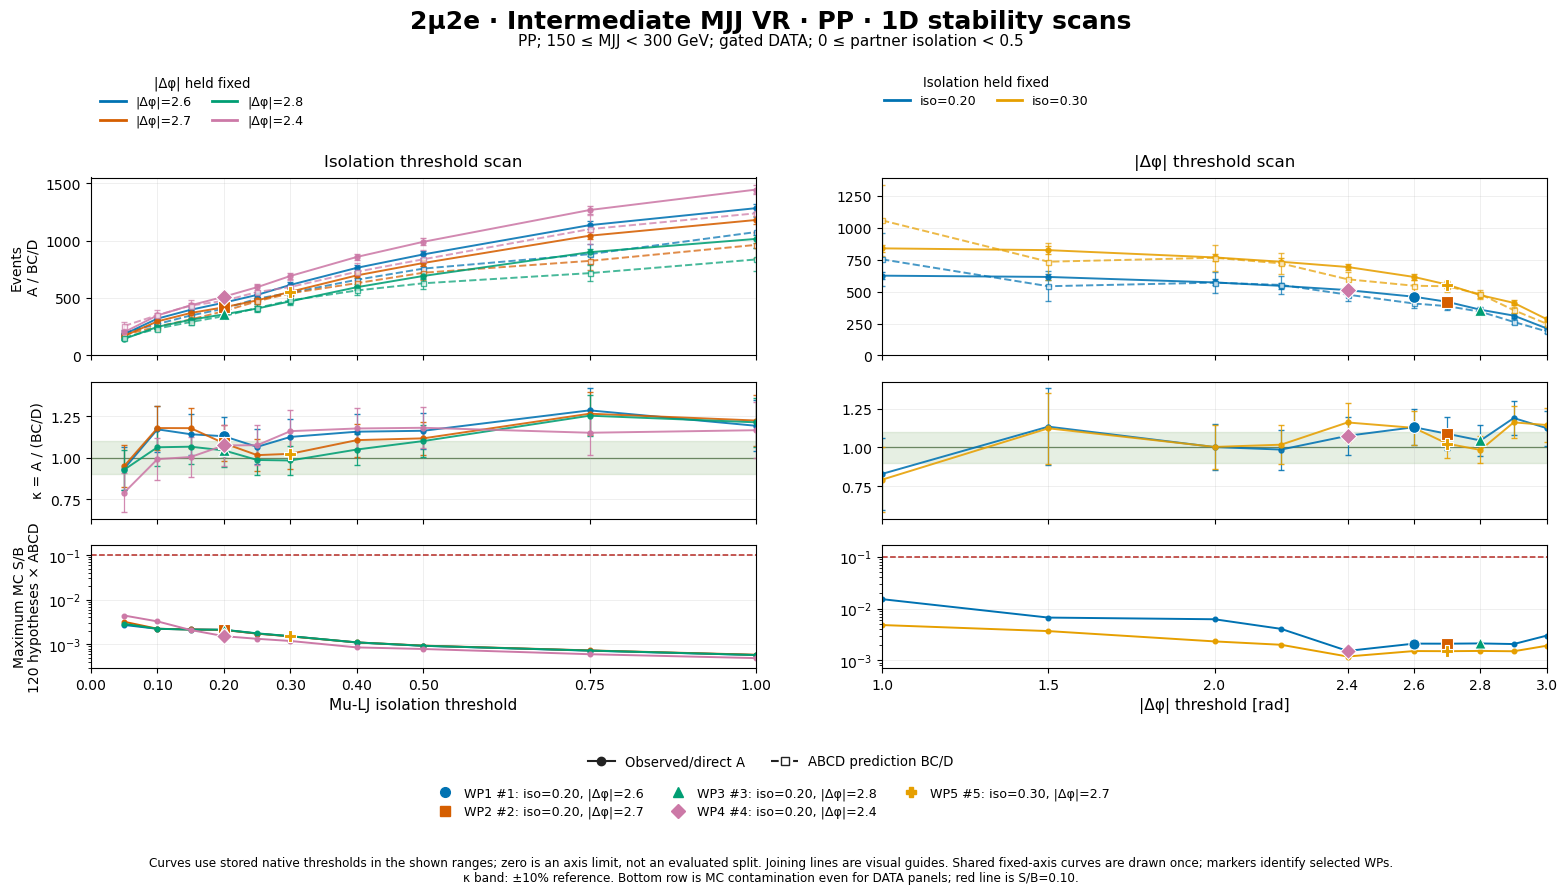

In [8]:
display(figure_lookup['scan_VR2_PP'])


## 7. PD: 1D stability comparisons

Use the same extended ranges and WPs to assess whether the PD closure pattern is stable away from the selected boundaries. DATA-gated points remain gaps in the curves.


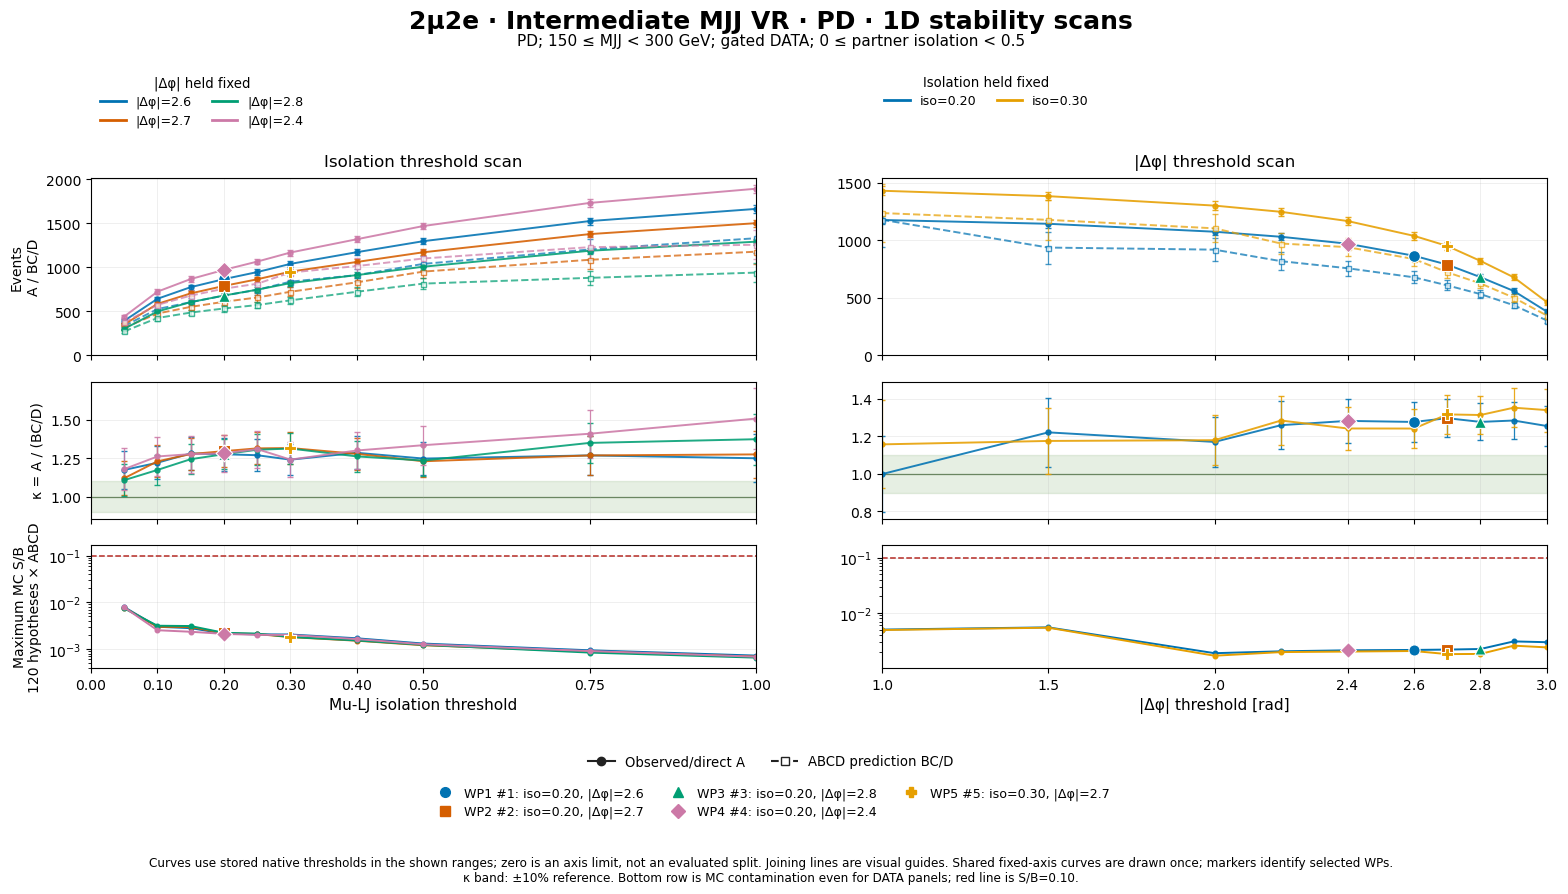

In [9]:
display(figure_lookup['scan_VR2_PD'])


## 8. DP: 1D stability comparisons

DP does not enter candidate selection. The extended scans retain its event counts, larger uncertainties and contamination gates, with the same cuts and marker identities as PP and PD.


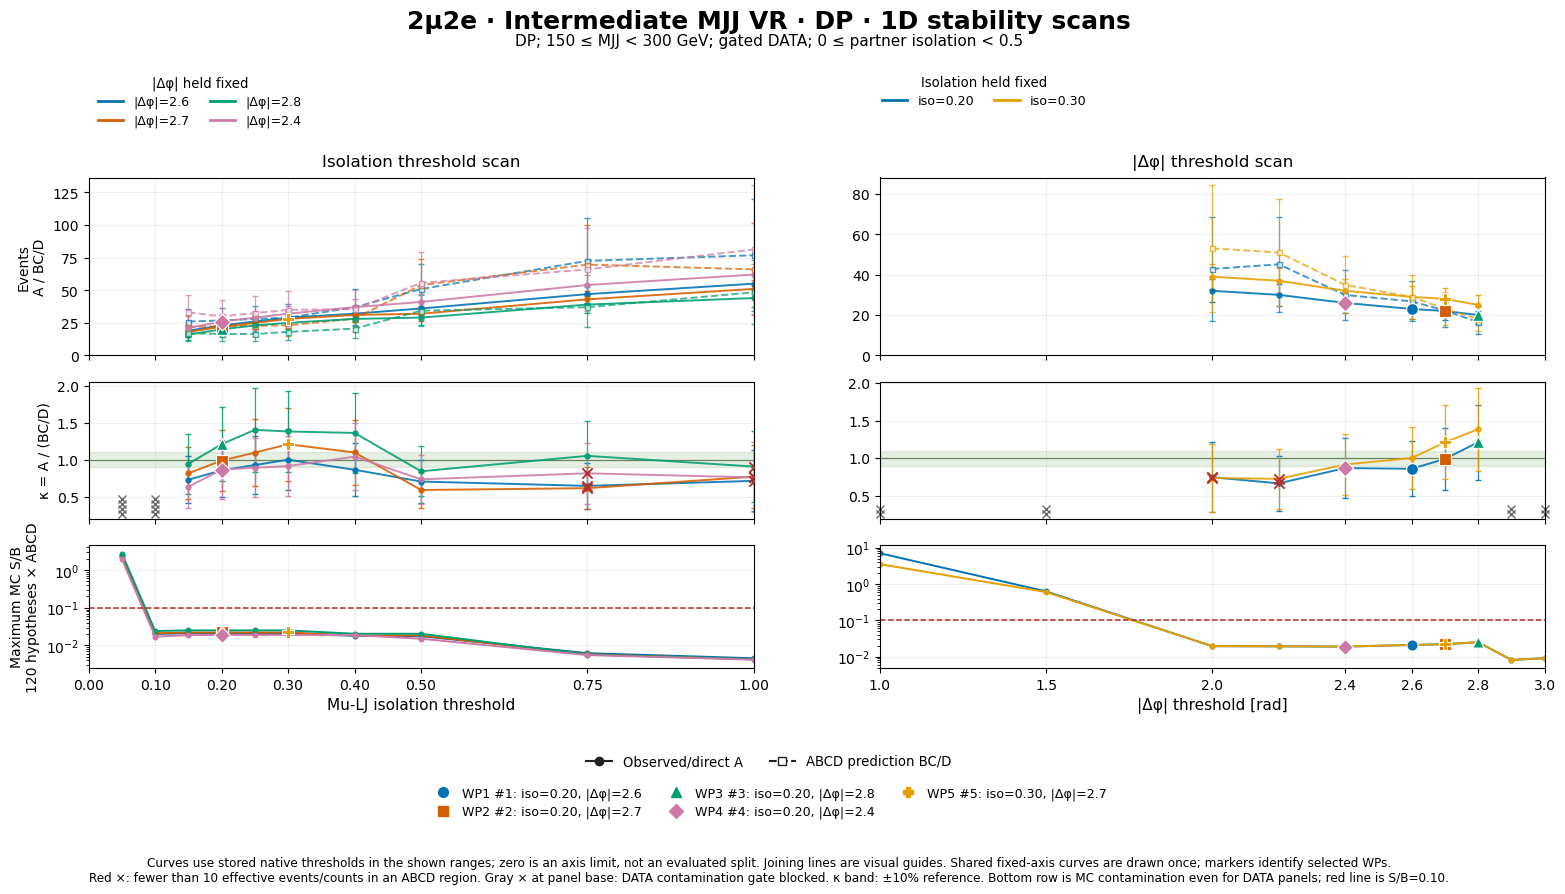

In [10]:
display(figure_lookup['scan_VR2_DP'])


## 9. Checks and numerical outputs

The focused comparison preserves the notebook-03 selections, native boundaries,
production weights, and all-hypothesis contamination gates. The full map is broad;
the candidate pool is local; detailed comparisons show only the five selected points.
The PP/PD κ values and their uncertainties must be read together. A suitable VR
comparison alone does not establish a numerical κ transfer to the nominal SR.


In [11]:
import hashlib
import json
from datetime import datetime, timezone

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
exports = {
    'selected_working_points': tables['working_points'],
    'selected_metrics': tables['ranking'],
    'selected_comparison': selected_table,
    'selected_comprehensive_numeric': summary_numeric,
    'selected_closure': tables['closure'],
    'selected_contamination': tables['purity'],
    'selected_signal_significance': tables['signal_significance'],
    'full_vr2_closure': tables['full_closure'],
    'full_vr2_contamination': tables['full_purity'],
    'candidate_pool_audit': tables['candidate_pool'],
    'figure_definitions': figure_definitions,
    'validation': tables['validation'],
    'input_manifest': tables['input_manifest'],
}
for name, frame in exports.items():
    frame.to_csv(OUTPUT_DIR / f'{name}.csv', index=False)
for figure, name in figures:
    figure.savefig(OUTPUT_DIR / f'{name}.png', dpi=110, facecolor='white')
implementation = {name: hashlib.sha256((NOTEBOOK_DIR / name).read_bytes()).hexdigest()
                  for name in ('abcd_finalize_common.py', 'abcd_finalize_plots.py')}
manifest = {'created_utc': datetime.now(timezone.utc).isoformat(),
            'configuration': CONFIG, 'methodology': results['metadata'],
            'figures': [name for _, name in figures],
            'table_rows': {name: len(frame) for name, frame in exports.items()},
            'implementation_sha256': implementation}
(OUTPUT_DIR / 'manifest.json').write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2, default=str) + chr(10))
validation_display = tables['validation'].copy()
validation_display['scope'] = (validation_display['scope']
    .str.replace('VR2_', 'Intermediate MJJ VR · ', regex=False)
    .str.replace('VR2', 'Intermediate MJJ VR', regex=False))
validation_display['check'] = validation_display['check'].str.replace(
    'VR2', 'Intermediate MJJ VR (150 ≤ MJJ < 300 GeV)', regex=False)
display(validation_display)
display(Markdown(f'[Focused numerical tables and previews]({OUTPUT_DIR.name}/)'))
print(f'Completed: {len(selected)} selected WPs, {len(figures)} figures, Intermediate MJJ VR (150 ≤ MJJ < 300 GeV), PP/PD/DP only.')


,scope,check,passed
0,Intermediate MJJ VR · PP,Complete 154-WP Intermediate MJJ VR (150 ≤ MJJ...,True
1,Intermediate MJJ VR · PD,Complete 154-WP Intermediate MJJ VR (150 ≤ MJJ...,True
2,Intermediate MJJ VR · DP,Complete 154-WP Intermediate MJJ VR (150 ≤ MJJ...,True
3,Intermediate MJJ VR,"Notebook-03 cuts, histogram identity, native b...",True
4,Local,16 unique native candidates; identical 60-mode...,True
5,Displayed,Exactly five ranked WPs; reference is not a fo...,True
6,Evaluation,PP and PD only; DP excluded from both selectio...,True
7,Evaluation,Selected PP/PD DATA retain the existing 120-mo...,True
8,Inputs,Cached tables only; no raw MC/signal/DATA or V...,True
9,SR,Nominal SR input is MC only; no nominal DATA a...,True


[Focused numerical tables and previews](07_2mu2e_VR2_focused_outputs/)

Completed: 5 selected WPs, 8 figures, Intermediate MJJ VR (150 ≤ MJJ < 300 GeV), PP/PD/DP only.


## Part II — Why does S/B increase toward lower Δφ?

The last three figures in Part I show **max(S/B_MC) over 120 hypotheses and all four ABCD regions**. The denominator is the **direct MC background yield in the corresponding region**, not the ABCD prediction B×C/D.

At fixed isolation, lowering the Δφ threshold expands A/B and contracts C/D. Geometry alone does not determine the ratio: the signal and background can decrease at different rates, and the signal hypothesis or region that gives the maximum can change.

The following calculation keeps all five existing candidates and adds the reference only for follow-up comparisons. Original inputs are read once for the nominal-MC composition and mass-inclusive studies. All 120 hypotheses are tested separately before displaying new VR DATA.


In [12]:
from abcd_finalize_common import finalize_comprehensive_run_comprehensive as run_comprehensive, finalize_comprehensive_export_comprehensive as export_comprehensive
from abcd_finalize_plots import finalize_comprehensive_plots_make_comprehensive_figures as make_comprehensive_figures, finalize_comprehensive_plots_comprehensive_figure_definitions as comprehensive_figure_definitions

comprehensive = run_comprehensive(results, CONFIG)
followup_tables = comprehensive['tables']
mass_tables = comprehensive['mass']['tables']
with pd.option_context('display.max_columns', None):
    display(followup_tables['working_points'])
    envelope = followup_tables['contamination_envelope']
    display(envelope.loc[np.isclose(envelope.tx, .20) & envelope.ty.isin([1., 1.5, 2.4, 2.6, 2.7]),
                         ['plane', 'tx', 'ty', 'worst_region', 'worst_sample',
                          'signal', 'background', 'max_S_B', 'neff_background']])


Mass-inclusive MC 20/138


Mass-inclusive MC 40/138


Mass-inclusive MC 60/138


Mass-inclusive MC 80/138


Mass-inclusive MC 100/138


Mass-inclusive MC 120/138


... (3 outputs left out)

Mass-inclusive approved VR DATA 60/68


Mass-inclusive approved VR DATA 68/68


,wp,tx,ty
0,Reference,0.3,2.6
1,WP1,0.2,2.6
2,WP2,0.2,2.7
3,WP3,0.2,2.8
4,WP4,0.2,2.4
5,WP5,0.3,2.7


,plane,tx,ty,worst_region,worst_sample,signal,background,max_S_B,neff_background
1,PP,0.2,1.0,C,4Mu_800GeV_1p2GeV_0p12mm,0.023667,1.560968,0.015162,2.675639
2,PP,0.2,1.5,C,4Mu_800GeV_5p0GeV_0p05mm,0.039572,5.918645,0.006686,2.885602
5,PP,0.2,2.4,A,2Mu2E_200GeV_0p25GeV_0p01mm,0.844630,556.570758,0.001518,7.912494
6,PP,0.2,2.6,A,2Mu2E_200GeV_0p25GeV_0p01mm,0.811283,386.473228,0.002099,5.134359
7,PP,0.2,2.7,A,2Mu2E_200GeV_0p25GeV_0p01mm,0.781820,373.484514,0.002093,4.811809
29,PD,0.2,1.0,C,4Mu_800GeV_0p25GeV_0p0025mm,0.186558,37.303508,0.005001,6.808636
30,PD,0.2,1.5,C,4Mu_800GeV_0p25GeV_0p0025mm,0.352640,64.259447,0.005488,12.151865
33,PD,0.2,2.4,C,4Mu_800GeV_0p25GeV_0p0025mm,0.803109,380.070830,0.002113,5.010477
34,PD,0.2,2.6,C,4Mu_800GeV_5p0GeV_0p05mm,0.896972,418.119992,0.002145,6.020186
35,PD,0.2,2.7,C,4Mu_800GeV_1p2GeV_0p012mm,0.949078,436.052230,0.002177,6.521161


In [13]:
followup_definitions = comprehensive_figure_definitions()
followup_figures = make_comprehensive_figures(comprehensive, CONFIG)
followup_lookup = {name: figure for figure, name in followup_figures}
assert len(followup_figures) == 17
for figure, _ in followup_figures:
    plt.close(figure)


### II.1. Separate the ABCD envelopes

Each colored curve is the maximum over 120 hypotheses **within one ABCD region**. The dashed envelope is the maximum of those four curves. The detailed table retains the maximizing model and region; neither is assumed to stay fixed.


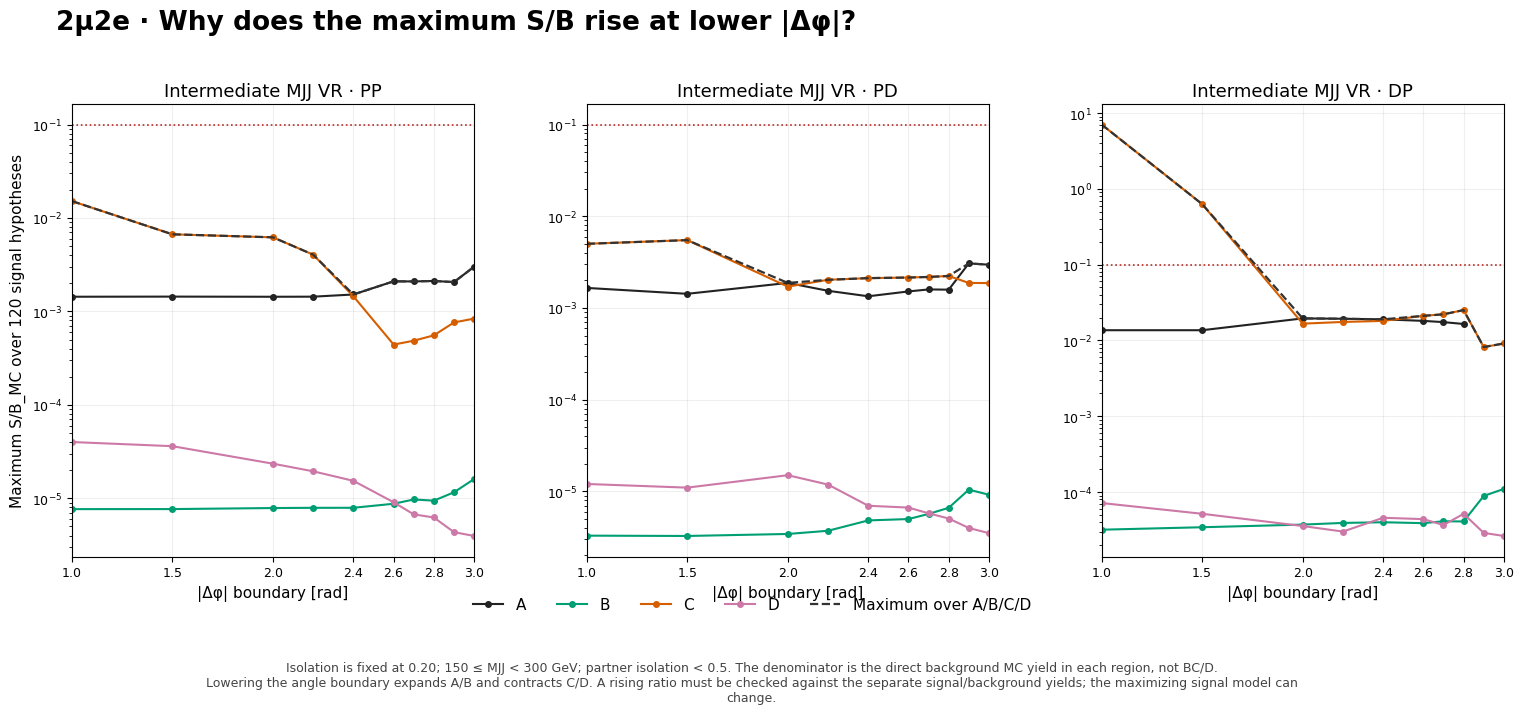

In [14]:
display(followup_lookup['sb_regions'])


### II.2. Follow the same signal hypothesis in C

For each VR, choose the most contaminating C-region model at (iso,Δφ)=(0.20,2.6), then hold that model fixed while scanning Δφ. Compare its signal retention with the background retention, and compare its S/B with the 120-model C envelope. The effective background MC count exposes ratios driven by very sparse support.

These retention ratios share events with their reference and are central-value diagnostics. They are not independent measurements with uncorrelated uncertainties. A maximum driven by C at low Δφ does not imply that C dominates the entire scan or that the trend is monotonic.


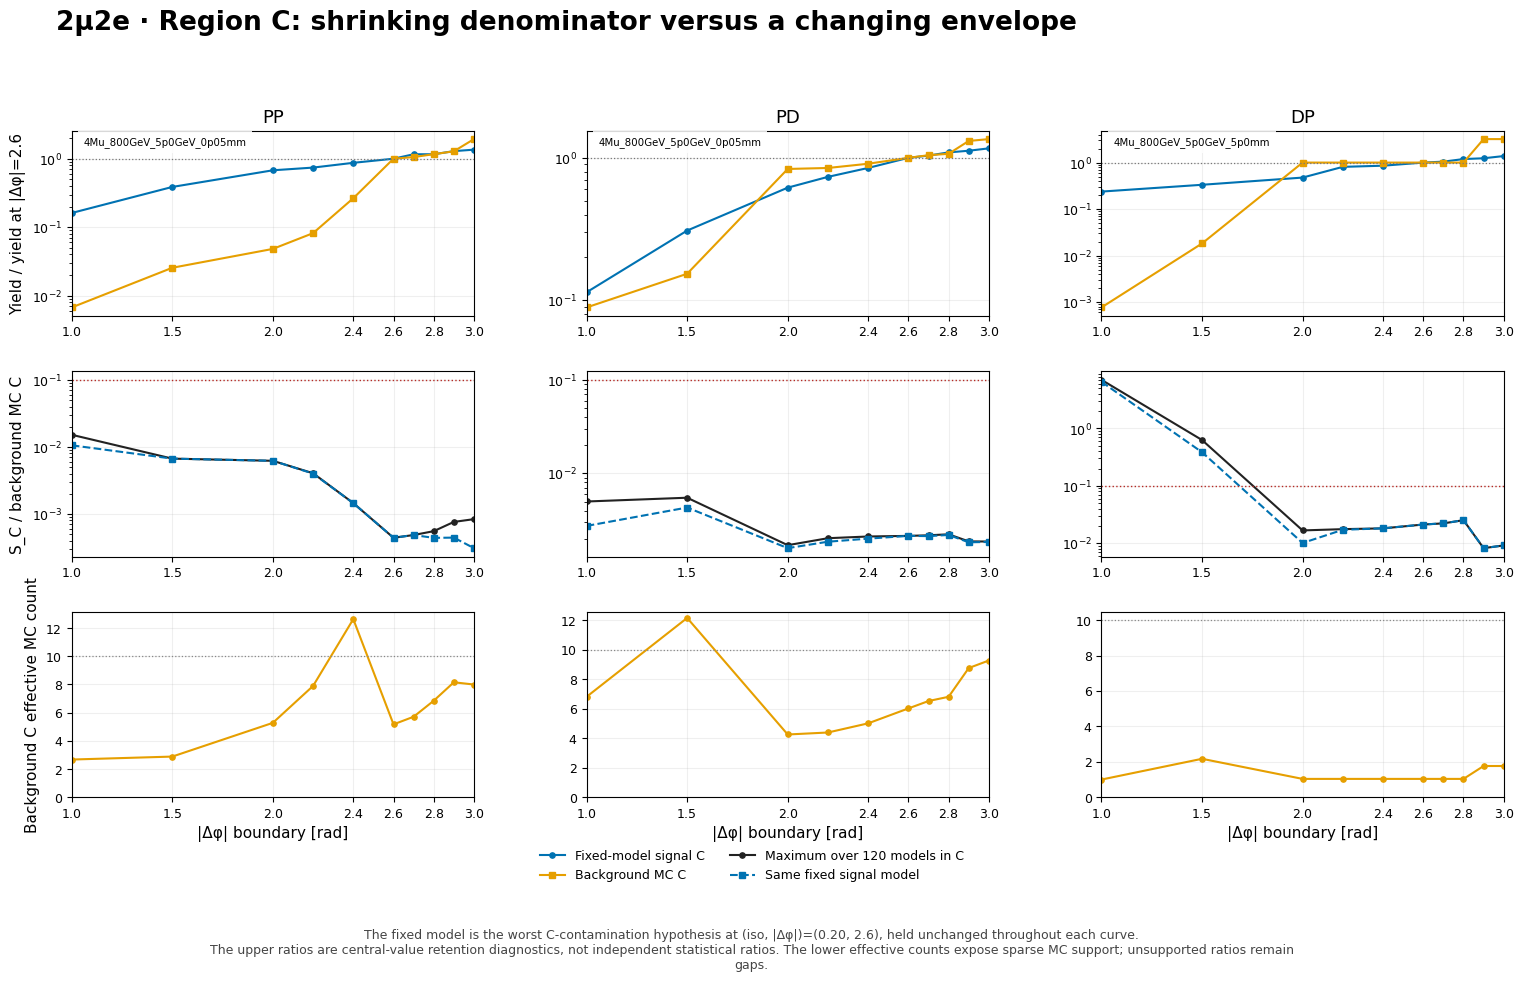

In [15]:
display(followup_lookup['sb_c_decomposition'])


## Part III — Does nominal background MC support the candidate choice?

Use **DD, MJJ≥150 GeV, 0≤partner isolation<0.5**, with only MC. Compare signal retention, direct background yield, process/sample composition, sumw², effective counts and A versus B×C/D at the same boundaries.

The first five-candidate selection remains based on the original nominal-MC significance. The added reference enables a direct suppression/retention comparison. Large changes caused by a few heavily weighted background events do not establish a robust improvement by themselves.


In [16]:
with pd.option_context('display.max_columns', None):
    display(followup_tables['nominal_summary'][['wp', 'tx', 'ty', 'A', 'A_error', 'neff_A',
        'pred', 'pred_error', 'kappa', 'kappa_error', 'min_sideband_neff',
        'signal_retention_median', 'signal_retention_q10', 'signal_retention_q90',
        'background_retention', 'z_ratio_median']])
    sample_A = followup_tables['nominal_samples'].query('region == "A"')
    display(sample_A.loc[sample_A.wp.isin(['Reference', 'WP1', 'WP2']) & sample_A['yield'].ne(0),
                         ['wp', 'sample', 'yield', 'error', 'neff']])


,wp,tx,ty,A,A_error,neff_A,pred,pred_error,kappa,kappa_error,min_sideband_neff,signal_retention_median,signal_retention_q10,signal_retention_q90,background_retention,z_ratio_median
0,Reference,0.3,2.6,24.924437,12.760609,3.815118,100.427708,100.690468,0.248183,0.279396,1.476978,1.000000,1.000000,1.000000,1.000000,1.000000
1,WP1,0.2,2.6,2.265319,1.149726,3.882130,35.174026,36.262028,0.064403,0.074005,1.955015,0.996000,0.982604,1.000000,0.090887,3.155835
2,WP2,0.2,2.7,2.162417,1.145899,3.561113,29.032750,30.478389,0.074482,0.087588,1.760364,0.972093,0.945199,0.981100,0.086759,3.116885
3,WP3,0.2,2.8,2.133242,1.145528,3.467919,23.344760,25.262082,0.091380,0.110391,1.538358,0.933779,0.888676,0.949251,0.085588,2.968342
4,WP4,0.2,2.4,2.960934,1.325391,4.990787,56.551093,58.161658,0.052359,0.058729,1.925578,1.018470,1.004838,1.030326,0.118796,2.847794
5,WP5,0.3,2.7,16.829344,10.425833,2.605631,126.196069,123.778785,0.133359,0.154710,1.459905,0.975788,0.961719,0.984319,0.675215,1.173793


,wp,sample,yield,error,neff
8,Reference,QCD_Pt1000,0.016903,0.007559,5.0
20,Reference,QCD_Pt170To300,21.982536,12.691623,3.0
28,Reference,QCD_Pt300To470,2.634908,1.317454,4.0
36,Reference,QCD_Pt470To600,0.187141,0.132329,2.0
44,Reference,QCD_Pt600To800,0.087524,0.050532,3.0
48,Reference,QCD_Pt800To1000,0.015426,0.006298,6.0
80,WP1,QCD_Pt1000,0.006761,0.004781,2.0
100,WP1,QCD_Pt300To470,1.976181,1.140948,3.0
108,WP1,QCD_Pt470To600,0.187141,0.132329,2.0
116,WP1,QCD_Pt600To800,0.087524,0.050532,3.0


### III.1. Signal retention and background composition


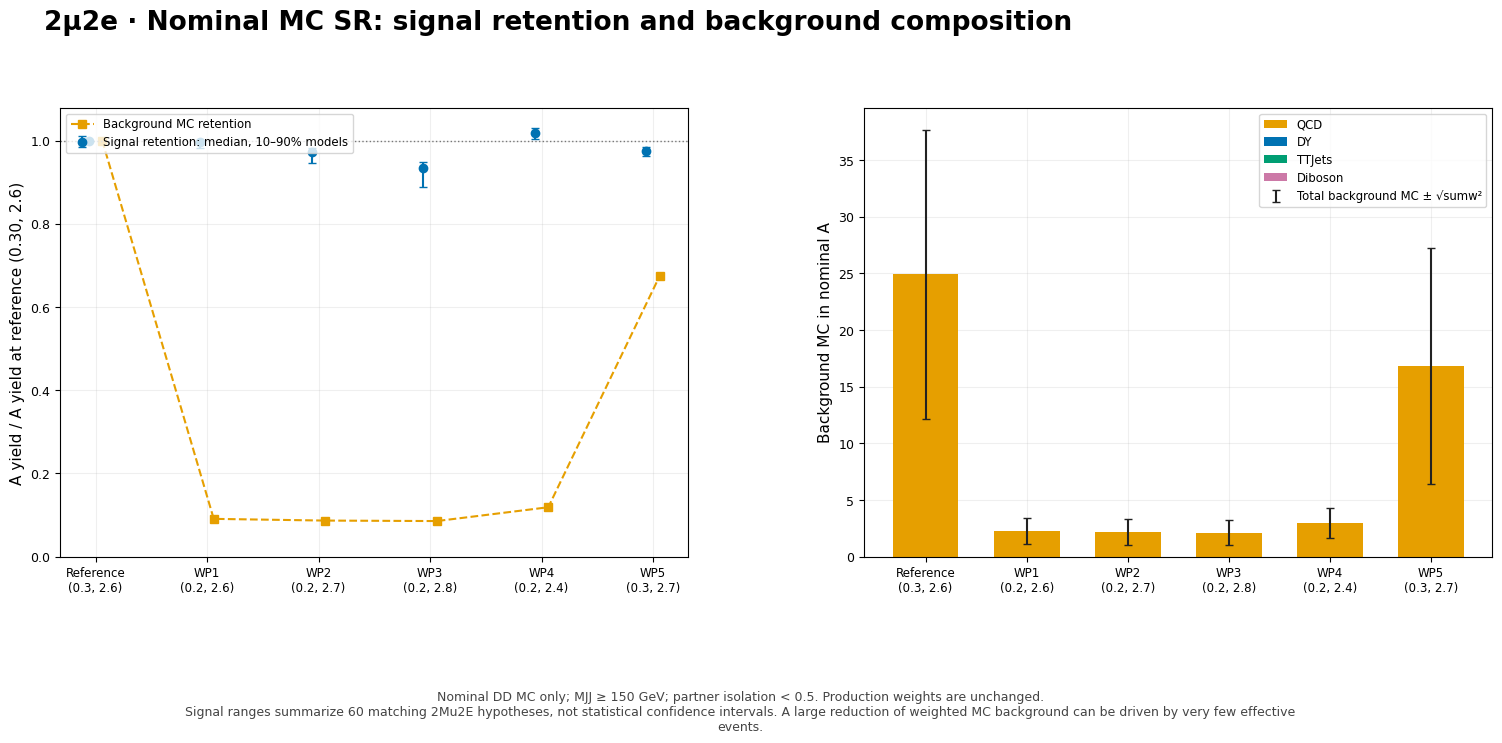

In [17]:
display(followup_lookup['nominal_retention_composition'])


### III.2. Nominal MC closure and statistical support


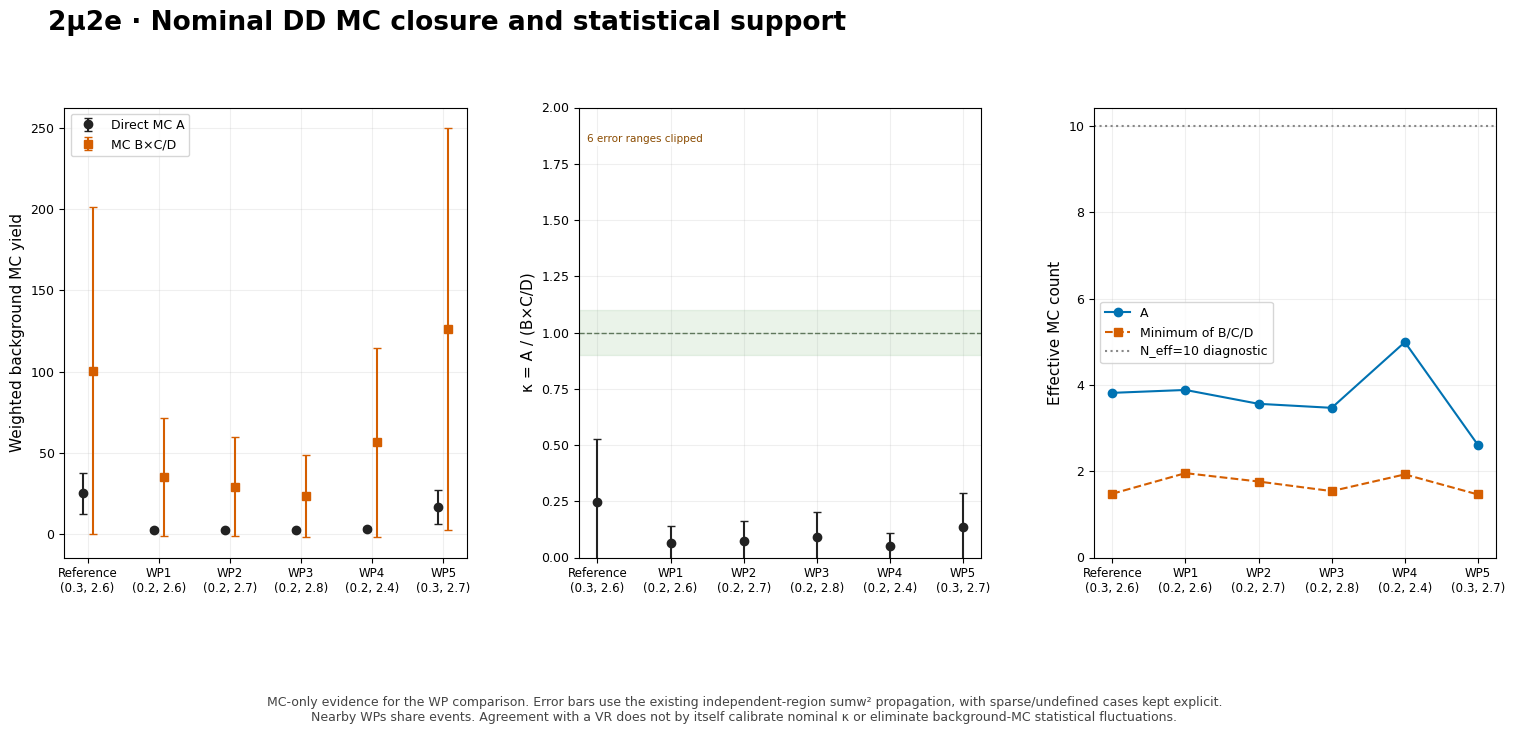

In [18]:
display(followup_lookup['nominal_mc_closure'])


## Part IV — Nominal B/C/D safety and expected-sensitivity eligibility

Check **all 120 signal hypotheses in B, C and D separately**, requiring S/B_MC<10% and valid positive background support. A is excluded from this sideband-purity test and stays blind.

A second, independent requirement is geometric: a new sideband cannot silently open the **original A at (0.30,2.6)**. The audit also conservatively protects the union of all five candidate A regions. Original-A overlap and additional candidate-A protection are reported separately. Overlap counts refer to native histogram cells, **not DATA events**.

If complete safe sidebands were available, one could estimate $\widehat B_A=N_B^{data}N_C^{data}/N_D^{data}$ and compare expected sensitivity using signal MC A. Statistical uncertainty, possible signal leakage and closure uncertainty would still have to enter the model. This would be **expected sensitivity using a DATA-constrained background**, not observed significance while A remains blind.

The notebook has no nominal DATA loader. Blocked estimates remain NaN with explicit reasons. Removing protected pieces from a sideband and applying the unmodified B×C/D formula is not used.


In [19]:
with pd.option_context('display.max_columns', None, 'display.max_colwidth', 100):
    display(followup_tables['nominal_bcd_audit'][['wp', 'region', 'background', 'background_error',
        'max_S_B', 'worst_sample', 'purity_pass', 'original_overlap_bins',
        'protected_overlap_bins', 'access_allowed', 'reason']])
    display(followup_tables['data_sensitivity_status'])


,wp,region,background,background_error,max_S_B,worst_sample,purity_pass,original_overlap_bins,protected_overlap_bins,access_allowed,reason
0,Reference,B,144.252446,118.696043,0.002015,2Mu2E_800GeV_1p2GeV_1p2mm,True,0,0,True,MC_AND_GEOMETRY_CHECKS_PASS_NO_DATA_READ
1,Reference,C,27.875996,13.151837,0.092904,2Mu2E_800GeV_1p2GeV_1p2mm,True,0,4,False,OVERLAPS_ADDITIONAL_CANDIDATE_A_PROTECTION
2,Reference,D,40.040549,13.010899,0.000306,2Mu2E_800GeV_5p0GeV_50p0mm,True,0,0,True,MC_AND_GEOMETRY_CHECKS_PASS_NO_DATA_READ
3,WP1,B,166.911563,119.374460,0.002986,2Mu2E_800GeV_1p2GeV_1p2mm,True,16,16,False,OVERLAPS_ORIGINAL_BLINDED_A
4,WP1,C,11.821221,8.044647,0.218328,2Mu2E_800GeV_1p2GeV_1p2mm,False,0,4,False,CONTAMINATION_OR_INVALID_MC_SUPPORT; OVERLAPS_ADDITIONAL_CANDIDATE_A_PROTECTION
5,WP1,D,56.095324,16.659471,0.000364,2Mu2E_800GeV_5p0GeV_50p0mm,True,0,0,True,MC_AND_GEOMETRY_CHECKS_PASS_NO_DATA_READ
6,WP2,B,158.080993,119.145704,0.002965,2Mu2E_800GeV_1p2GeV_1p2mm,True,14,14,False,OVERLAPS_ORIGINAL_BLINDED_A
7,WP2,C,11.924123,8.045193,0.324280,2Mu2E_800GeV_0p25GeV_0p25mm,False,4,8,False,CONTAMINATION_OR_INVALID_MC_SUPPORT; OVERLAPS_ORIGINAL_BLINDED_A; OVERLAPS_ADDITIONAL_CANDIDATE_...
8,WP2,D,64.925895,18.223641,0.000731,2Mu2E_800GeV_1p2GeV_1p2mm,True,2,2,False,OVERLAPS_ORIGINAL_BLINDED_A
9,WP3,B,147.488067,118.912700,0.002997,2Mu2E_800GeV_1p2GeV_1p2mm,True,12,12,False,OVERLAPS_ORIGINAL_BLINDED_A


,wp,tx,ty,all_BCD_purity_pass,all_BCD_access_allowed,nominal_data_evaluated,status,reason,data_B,data_C,data_D,predicted_background,expected_z
0,Reference,0.3,2.6,True,False,False,BLOCKED,OVERLAPS_ADDITIONAL_CANDIDATE_A_PROTECTION,NaN,NaN,NaN,NaN,NaN
1,WP1,0.2,2.6,False,False,False,BLOCKED,CONTAMINATION_OR_INVALID_MC_SUPPORT; OVERLAPS_ADDITIONAL_CANDIDATE_A_PROTECTION | OVERLAPS_ORIGI...,NaN,NaN,NaN,NaN,NaN
2,WP2,0.2,2.7,False,False,False,BLOCKED,CONTAMINATION_OR_INVALID_MC_SUPPORT; OVERLAPS_ORIGINAL_BLINDED_A; OVERLAPS_ADDITIONAL_CANDIDATE_...,NaN,NaN,NaN,NaN,NaN
3,WP3,0.2,2.8,False,False,False,BLOCKED,CONTAMINATION_OR_INVALID_MC_SUPPORT; OVERLAPS_ORIGINAL_BLINDED_A; OVERLAPS_ADDITIONAL_CANDIDATE_...,NaN,NaN,NaN,NaN,NaN
4,WP4,0.2,2.4,False,False,False,BLOCKED,CONTAMINATION_OR_INVALID_MC_SUPPORT | OVERLAPS_ORIGINAL_BLINDED_A,NaN,NaN,NaN,NaN,NaN
5,WP5,0.3,2.7,False,False,False,BLOCKED,CONTAMINATION_OR_INVALID_MC_SUPPORT; OVERLAPS_ORIGINAL_BLINDED_A; OVERLAPS_ADDITIONAL_CANDIDATE_...,NaN,NaN,NaN,NaN,NaN


### IV.1. Nominal sideband contamination


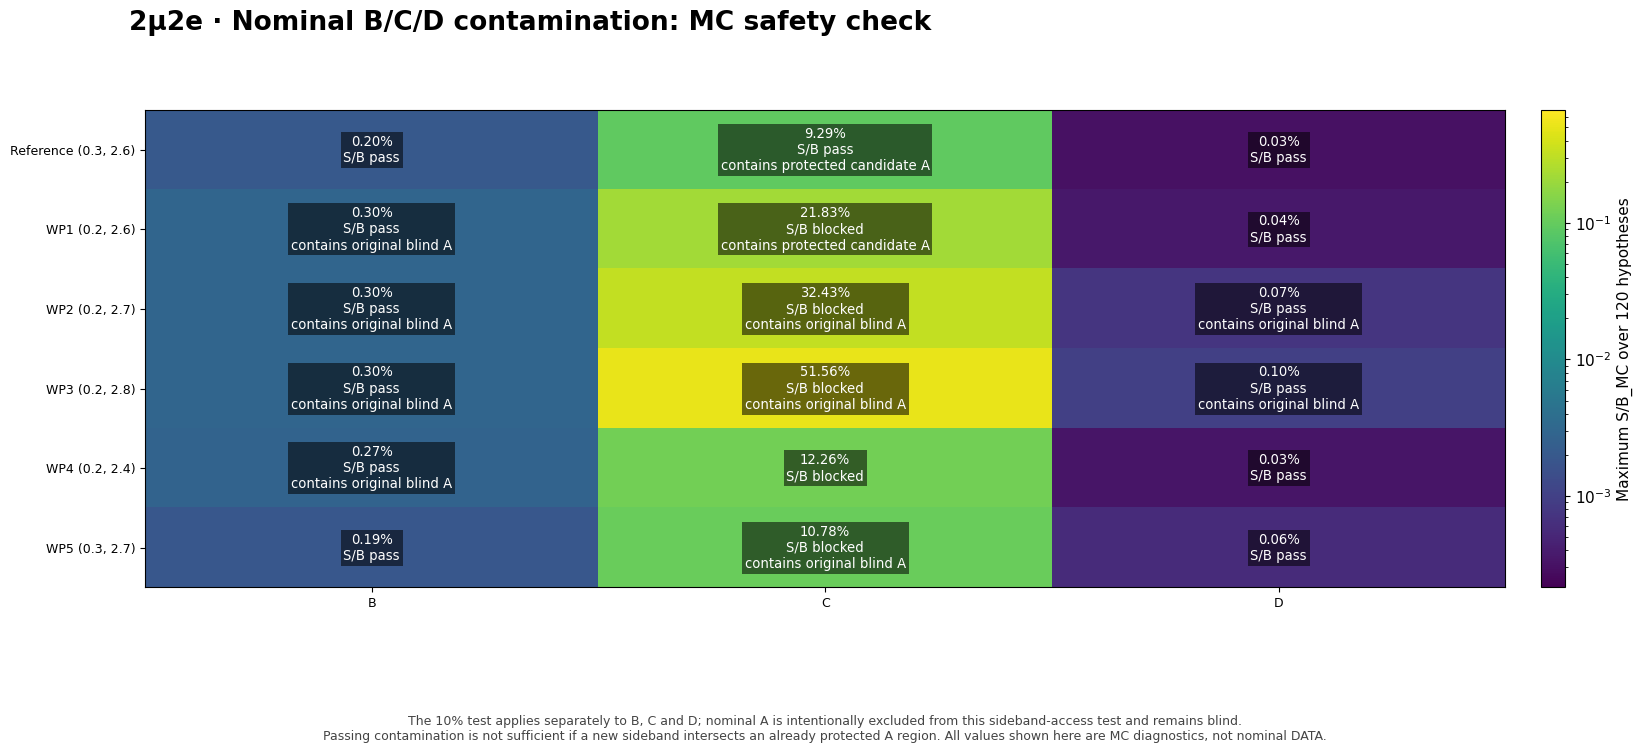

In [20]:
display(followup_lookup['nominal_bcd_purity'])


### IV.2. Old A inside new B/C/D


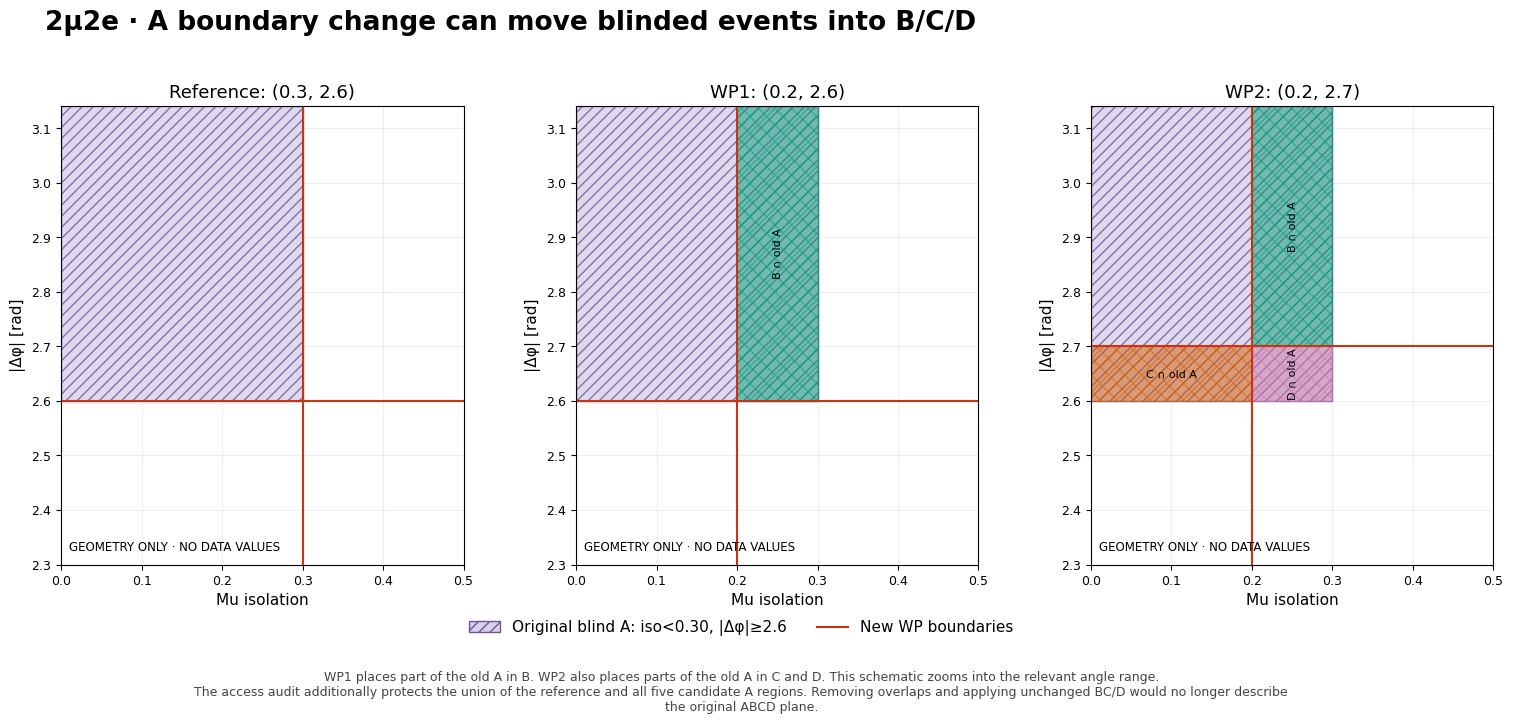

In [21]:
display(followup_lookup['nominal_blind_overlap'])


### IV.3. DATA-based expected-sensitivity status


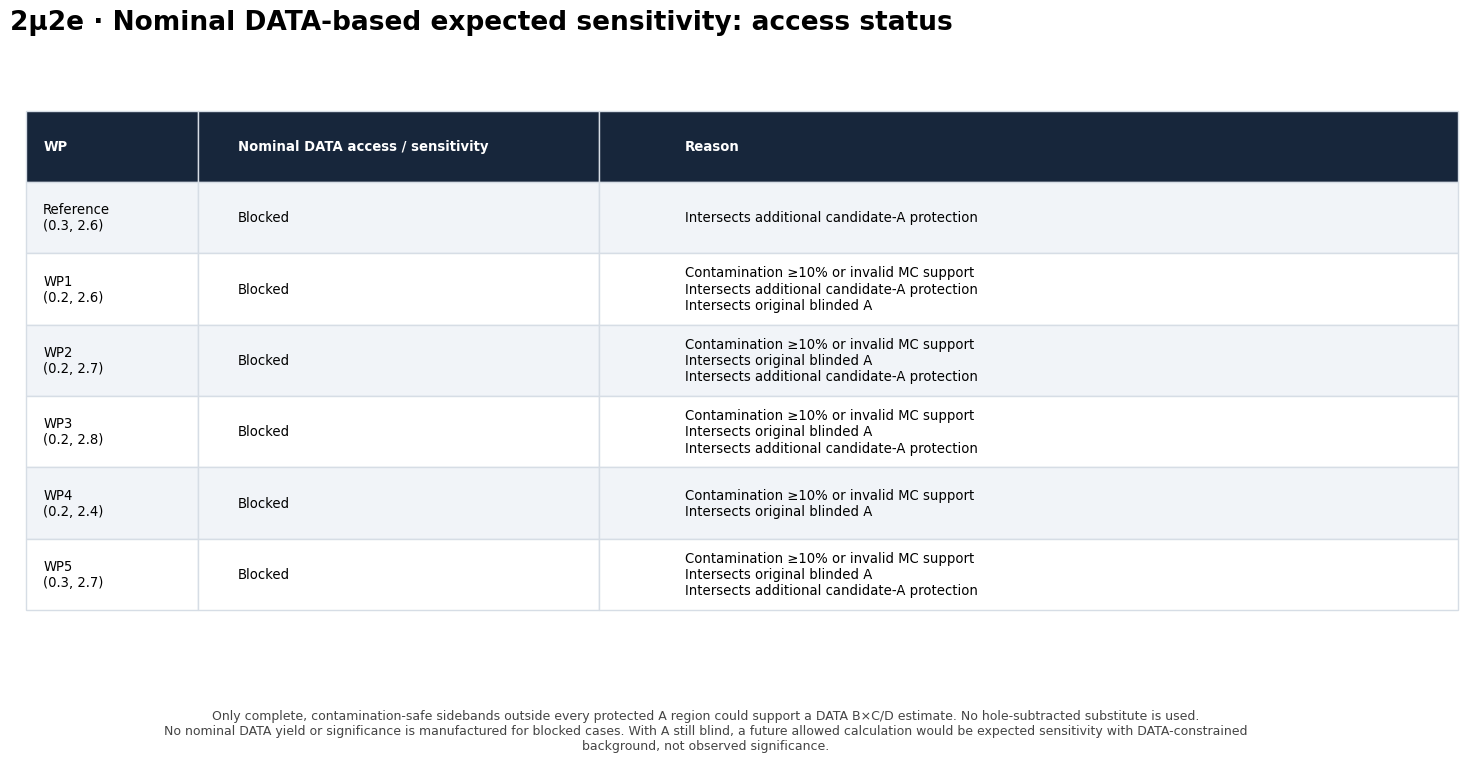

In [22]:
display(followup_lookup['nominal_data_access'])


### IV.4. Potential sideband-signal bias of B×C/D

For each **single** signal hypothesis, evaluate $r_R=S_R/B_R^{MC}$ and

$$\frac{(B_B+S_B)(B_C+S_C)/(B_D+S_D)}{B_BB_C/B_D}-1
=\frac{(1+r_B)(1+r_C)}{1+r_D}-1.$$

The same model supplies B, C and D before taking extrema across models. Multiplying independently maximized regional contaminations would mix different hypotheses. This is an MC signal-injection diagnostic, not a measured DATA bias.


In [23]:
display(followup_tables['nominal_signal_bias_summary'])


,wp,min_bias,max_bias,worst_sample,worst_bias
0,Reference,0.0,0.094864,2Mu2E_800GeV_1p2GeV_1p2mm,0.094864
1,WP1,0.0,0.221578,2Mu2E_800GeV_1p2GeV_1p2mm,0.221578
2,WP2,0.0,0.326754,2Mu2E_800GeV_0p25GeV_0p25mm,0.326754
3,WP3,0.0,0.517891,2Mu2E_800GeV_0p25GeV_0p25mm,0.517891
4,WP4,0.0,0.124632,2Mu2E_800GeV_0p25GeV_0p25mm,0.124632
5,WP5,0.0,0.109103,2Mu2E_800GeV_0p25GeV_0p25mm,0.109103


## Part V — Closure with the physical mass range unrestricted

Keep **PP · PD · DP** and 0≤partner isolation<0.5. Remove the previous 150 and 300 GeV mass boundaries. The physical support is **0≤MJJ<∞**, including histogram overflow. Invalid/unphysical numeric mass underflow is excluded consistently and recorded in an MC-only flow audit.

The disjoint MC components **[0,150), [150,300), [300,∞)** must add back to the inclusive sumw and sumw². The intermediate component is checked against notebook 03. No DD DATA or mass-component DATA are projected.

Recompute the 120-hypothesis × ABCD gate before opening these disjoint VR DATA. Recompute the exact displayed-bin mask as well: S/B≥10%, nonpositive MC background or invalid support hides the DATA bin before color normalization. The bin mask is for distribution display; integrated ABCD tests retain their own gate.

Low-mass background may dilute contamination, while high-mass signal may increase it; neither outcome is assumed. A good inclusive closure can also conceal a discrepancy in a smaller mass component, so keep the intermediate-mass comparison alongside it.


In [24]:
with pd.option_context('display.max_columns', None):
    display(mass_tables['selected_closure'][['wp', 'plane', 'source', 'tx', 'ty', 'A', 'B', 'C', 'D',
        'pred', 'pred_error', 'kappa', 'kappa_error', 'neff_min', 'max_S_B', 'approved']])
    # Audit each signal hypothesis separately; never sum alternative hypotheses.
    flow = mass_tables['mass_flow_audit'].copy()
    flow['abs_mass_underflow_sumw'] = flow.mass_underflow_sumw.abs()
    display(flow.groupby(['source', 'plane']).agg(
        files=('sample', 'nunique'),
        files_with_excluded_mass=('mass_underflow_sumw2', lambda values: int((values > 0).sum())),
        max_abs_excluded_sumw=('abs_mass_underflow_sumw', 'max'),
        max_excluded_sumw2=('mass_underflow_sumw2', 'max')))


,wp,plane,source,tx,ty,A,B,C,D,pred,pred_error,kappa,kappa_error,neff_min,max_S_B,approved
0,Reference,PP,MC,0.3,2.6,1795.759336,2484.733704,829.402460,1756.733171,1173.111706,326.840955,1.530766,0.792393,5.253960,0.080186,True
1,Reference,PP,DATA,0.3,2.6,1207.000000,1756.000000,856.000000,1834.000000,819.594329,39.160459,1.472680,0.082147,856.000000,0.080186,True
2,Reference,PD,MC,0.3,2.6,585.713566,1847.400278,1154.098913,2781.071164,766.640811,231.508499,0.764000,0.312835,13.076137,0.083016,True
3,Reference,PD,DATA,0.3,2.6,2103.000000,1581.000000,1548.000000,1704.000000,1436.260563,62.031832,1.464219,0.070843,1548.000000,0.083016,True
4,Reference,DP,MC,0.3,2.6,26.223686,133.310270,34.237155,100.698971,45.324836,30.515458,0.578572,0.464685,3.395987,0.748563,False
5,Reference,DP,DATA,0.3,2.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.748563,False
6,WP1,PP,MC,0.2,2.6,1045.784160,3234.708880,486.283587,2099.852044,749.093652,239.031530,1.396066,0.875711,3.428801,0.137363,False
7,WP1,PP,DATA,0.2,2.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.137363,False
8,WP1,PD,MC,0.2,2.6,469.696558,1963.417286,1056.069089,2879.100988,720.191585,224.836643,0.652183,0.286216,10.511465,0.103292,False
9,WP1,PD,DATA,0.2,2.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.103292,False


files  files_with_excluded_mass  \
source            plane                                    
Background        DP        18                         0   
                  PD        18                         0   
                  PP        18                         0   
Signal hypothesis DP       120                         0   
                  PD       120                         0   
                  PP       120                         0   

                         max_abs_excluded_sumw  max_excluded_sumw2  
source            plane                                             
Background        DP                       0.0                 0.0  
                  PD                       0.0                 0.0  
                  PP                       0.0                 0.0  
Signal hypothesis DP                       0.0                 0.0  
                  PD                       0.0                 0.0  
                  PP                       0.0                 0.0

### V.1. Inclusive-mass versus intermediate-mass closure


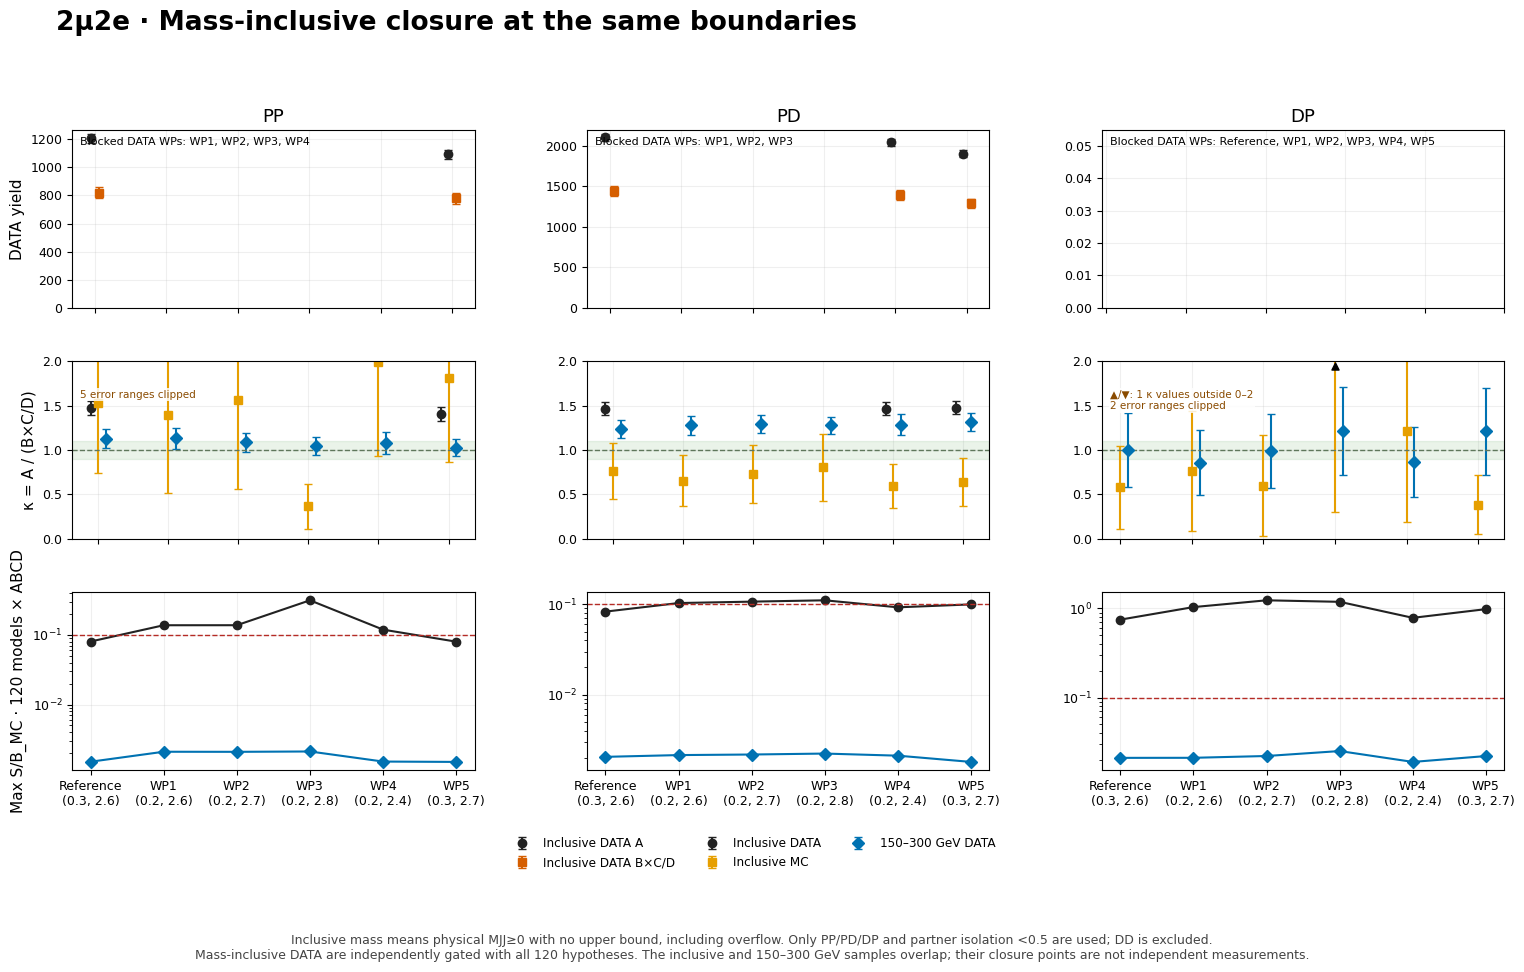

In [25]:
display(followup_lookup['mass_inclusive_closure'])


### V.2. Low/intermediate/high mass contributions


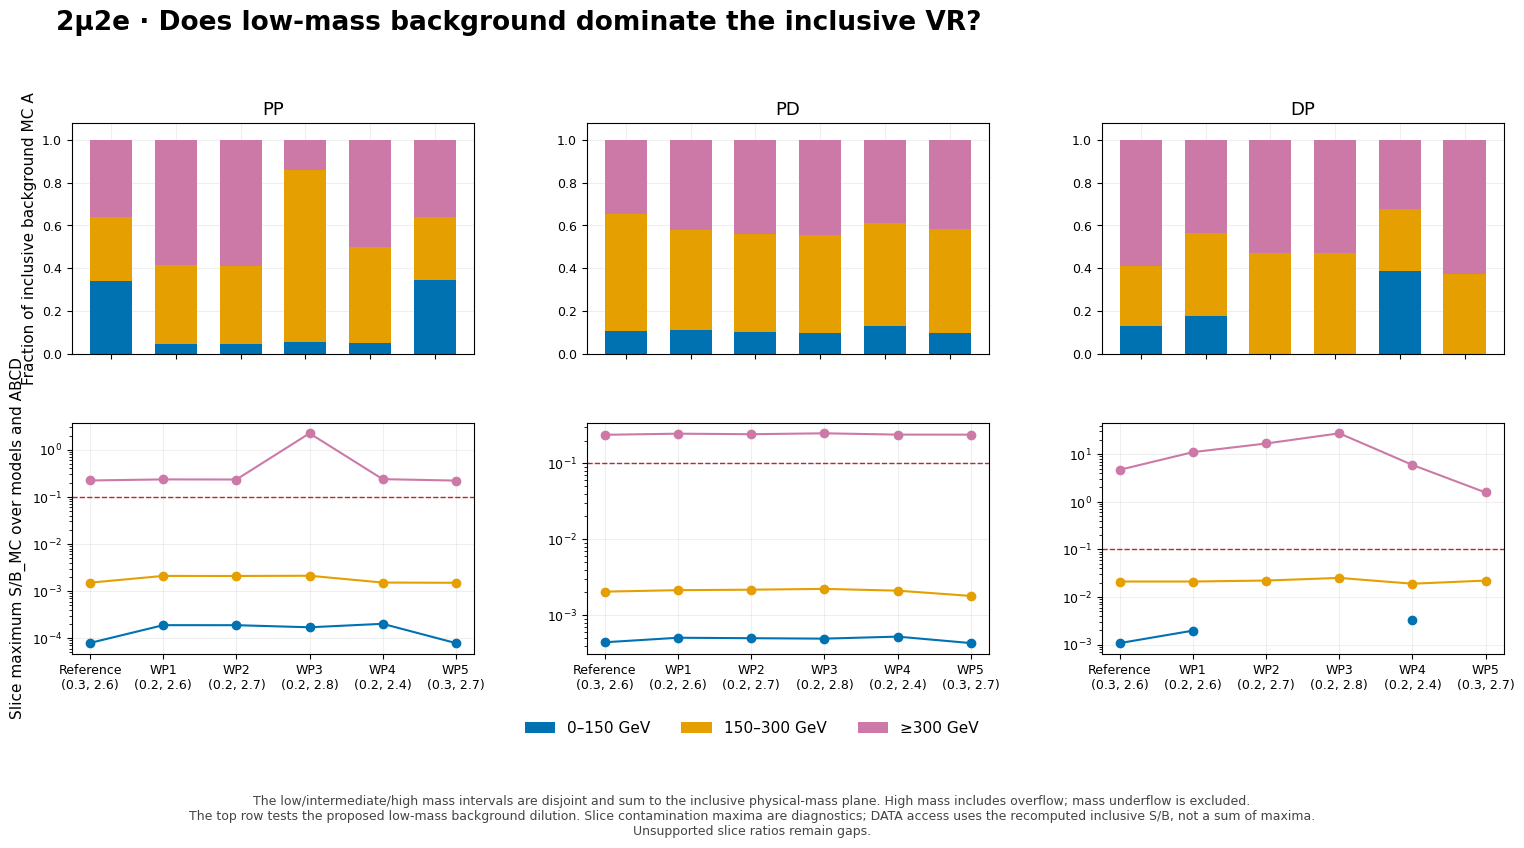

In [26]:
display(followup_lookup['mass_components'])


### V.3. All-mass ABCD contamination


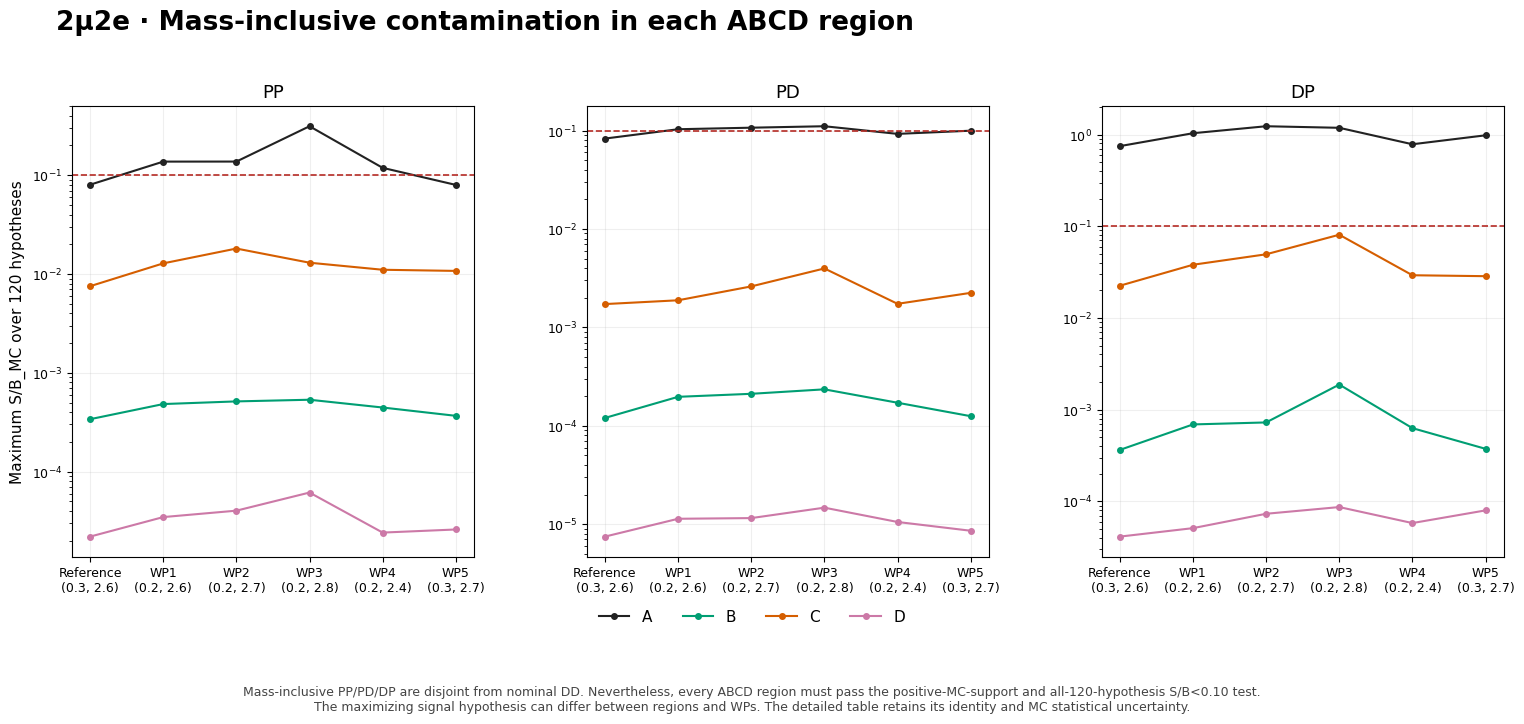

In [27]:
display(followup_lookup['mass_purity_selected'])


### V.4. Approved reference DATA and displayed-bin blinding

The reference is checked independently of WP1/WP2. An approved integrated plane can still contain individual contaminated or unsupported bins: those bins remain hatched and never contribute to the color normalization. A plane failing its integrated gate remains fully hidden.


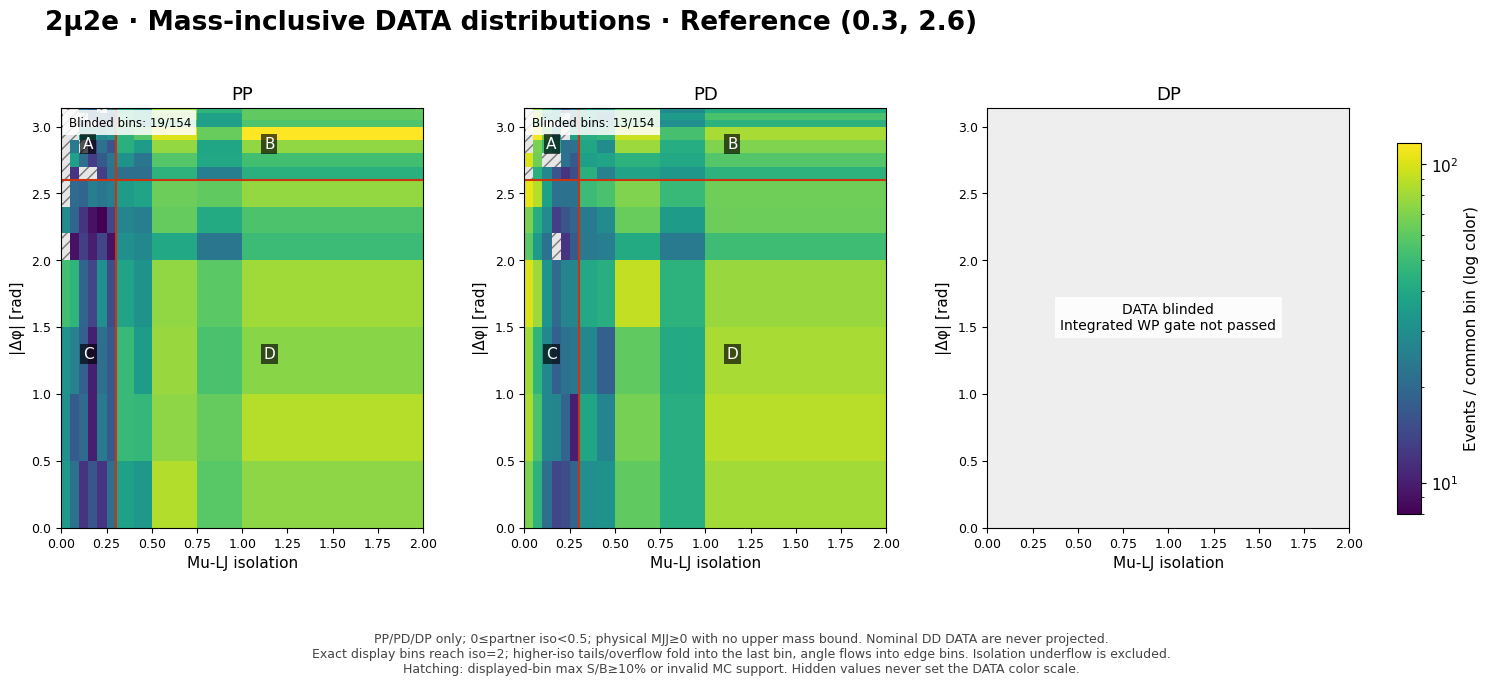

In [28]:
display(followup_lookup['mass_data_planes_Reference'])


### V.5. Gated all-mass DATA distribution at WP1


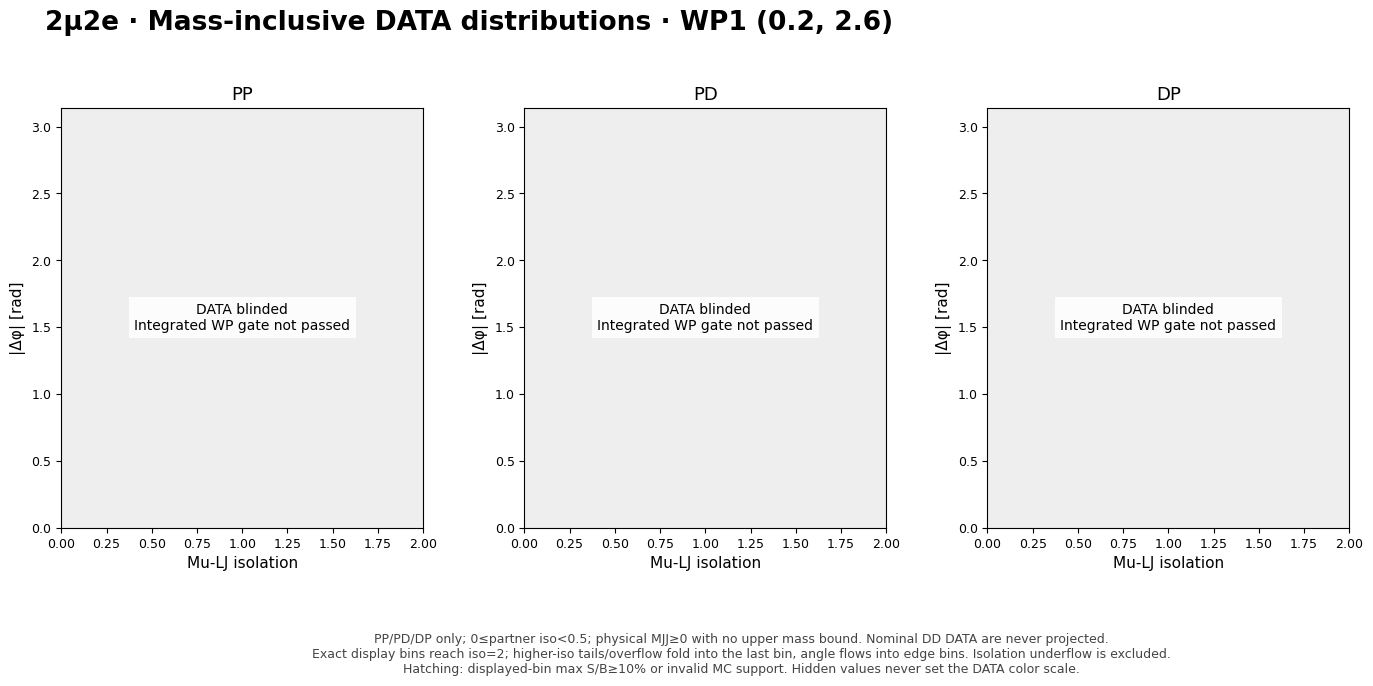

In [29]:
display(followup_lookup['mass_data_planes_WP1'])


### V.6. Gated all-mass DATA distribution at WP2


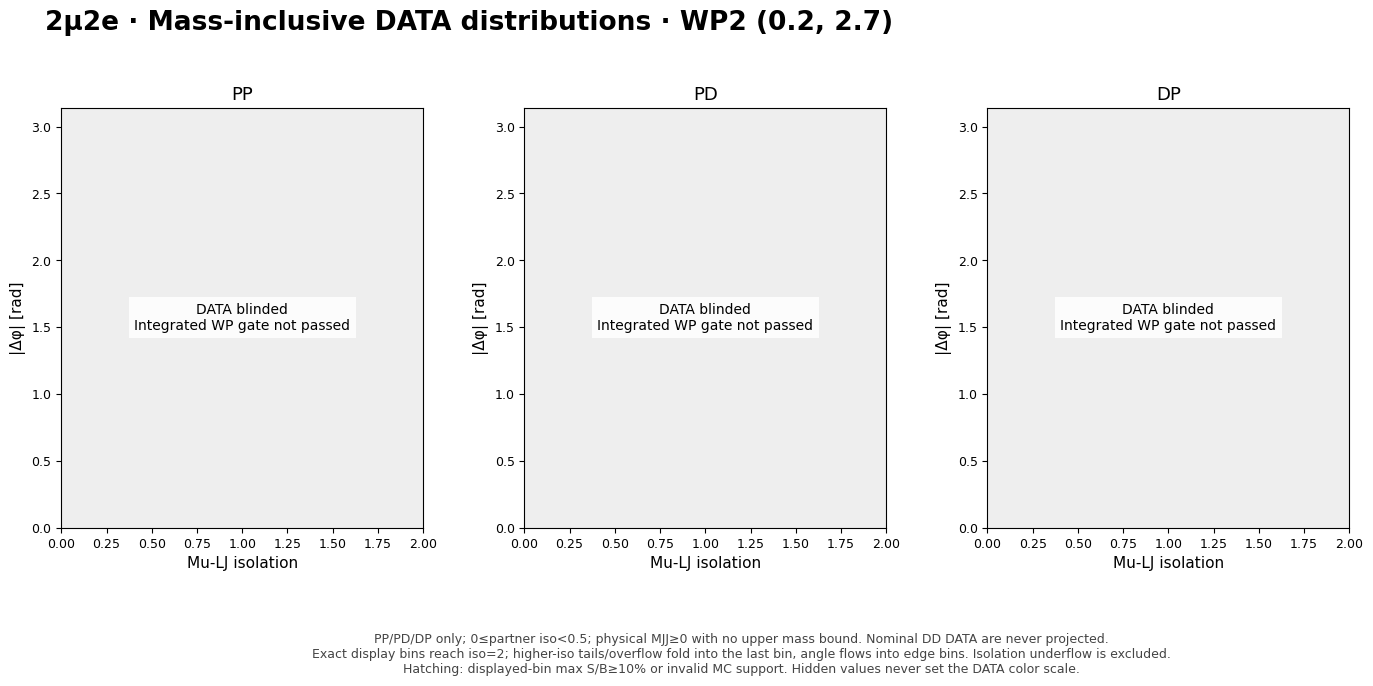

In [30]:
display(followup_lookup['mass_data_planes_WP2'])


### V.7. All-mass MC support at WP2


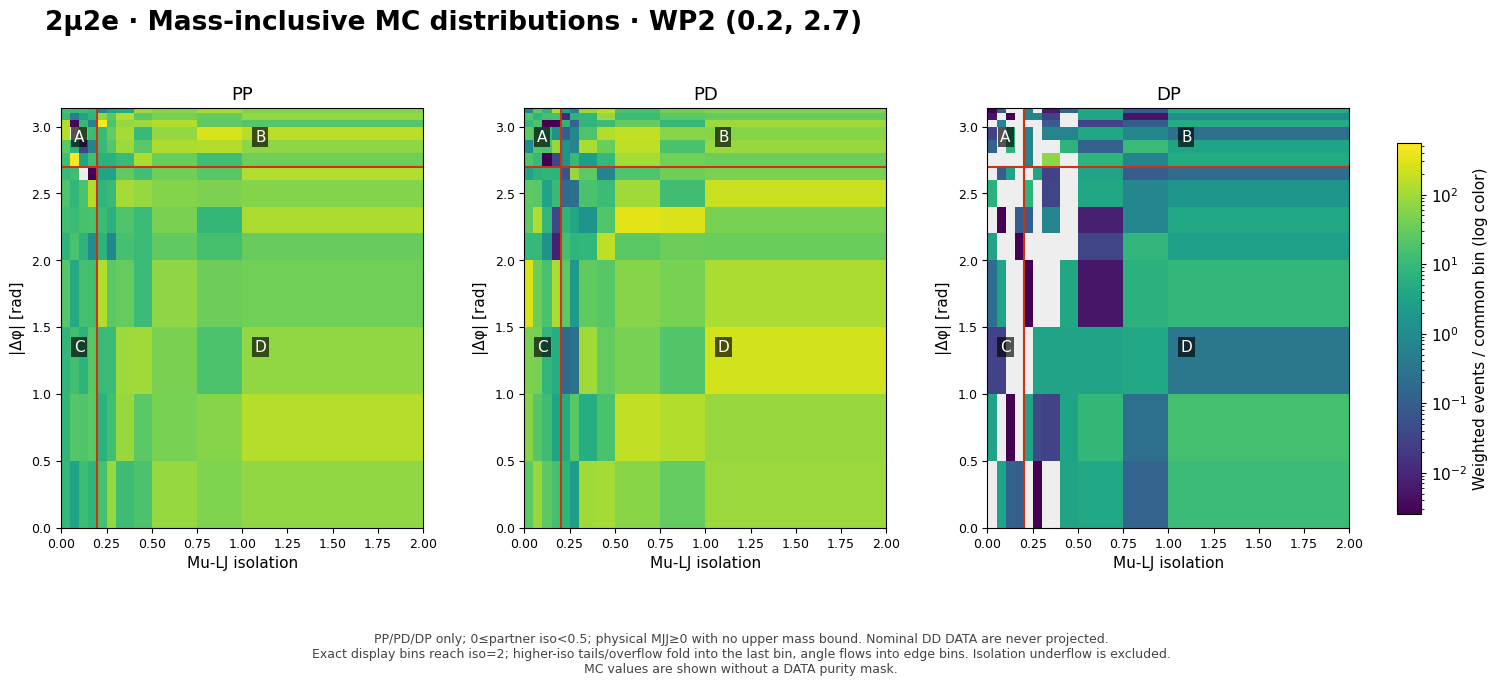

In [31]:
display(followup_lookup['mass_mc_planes_WP2'])


### V.8. All-mass PP stability scan


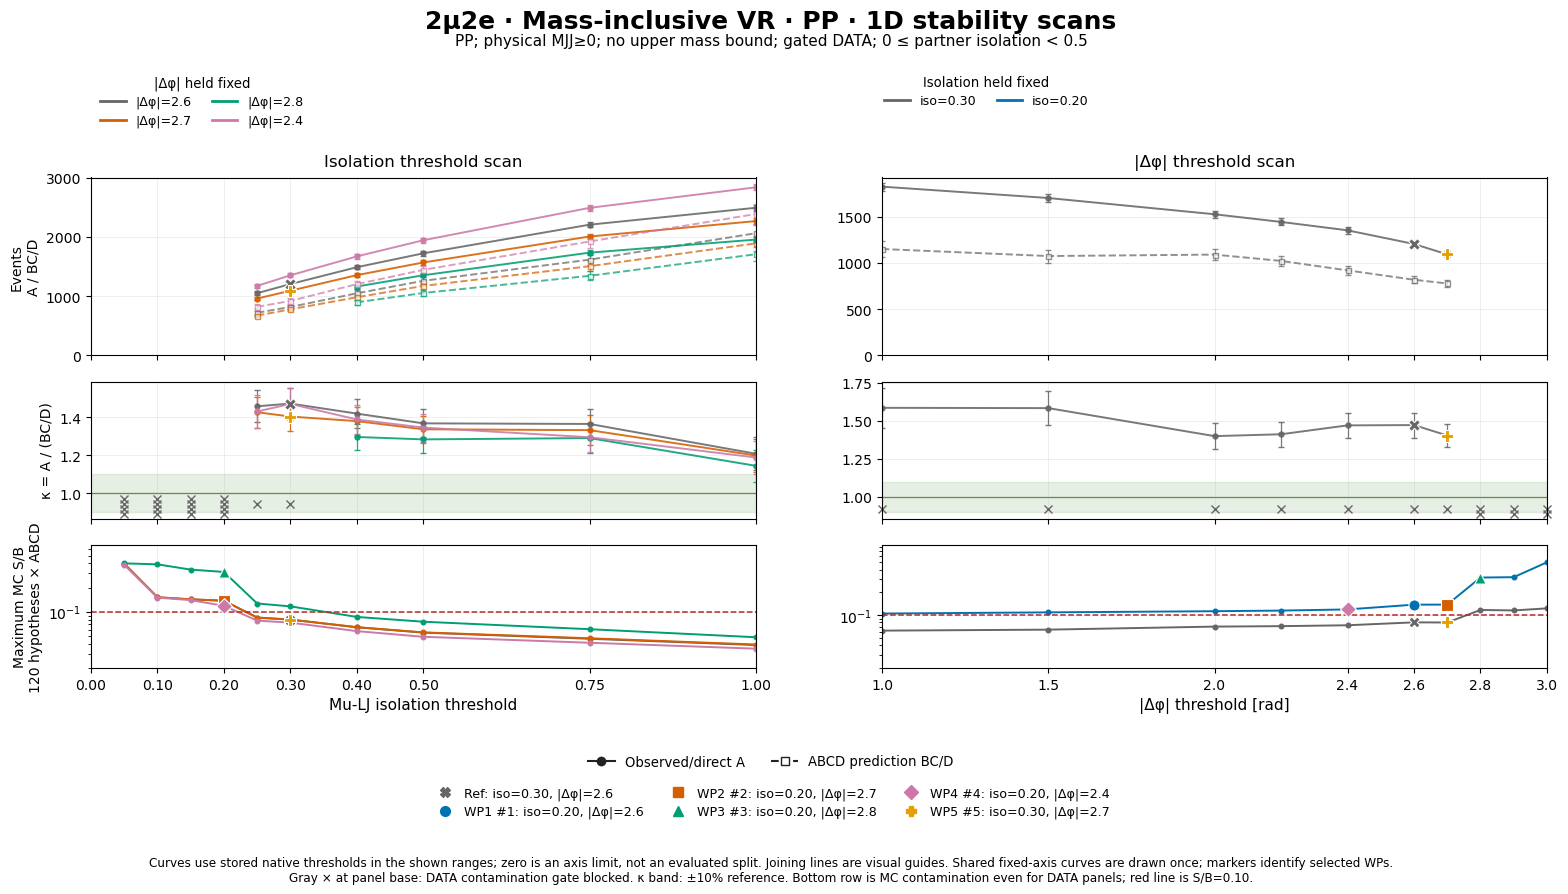

In [32]:
display(followup_lookup['mass_scan_PP'])


### V.9. All-mass PD stability scan


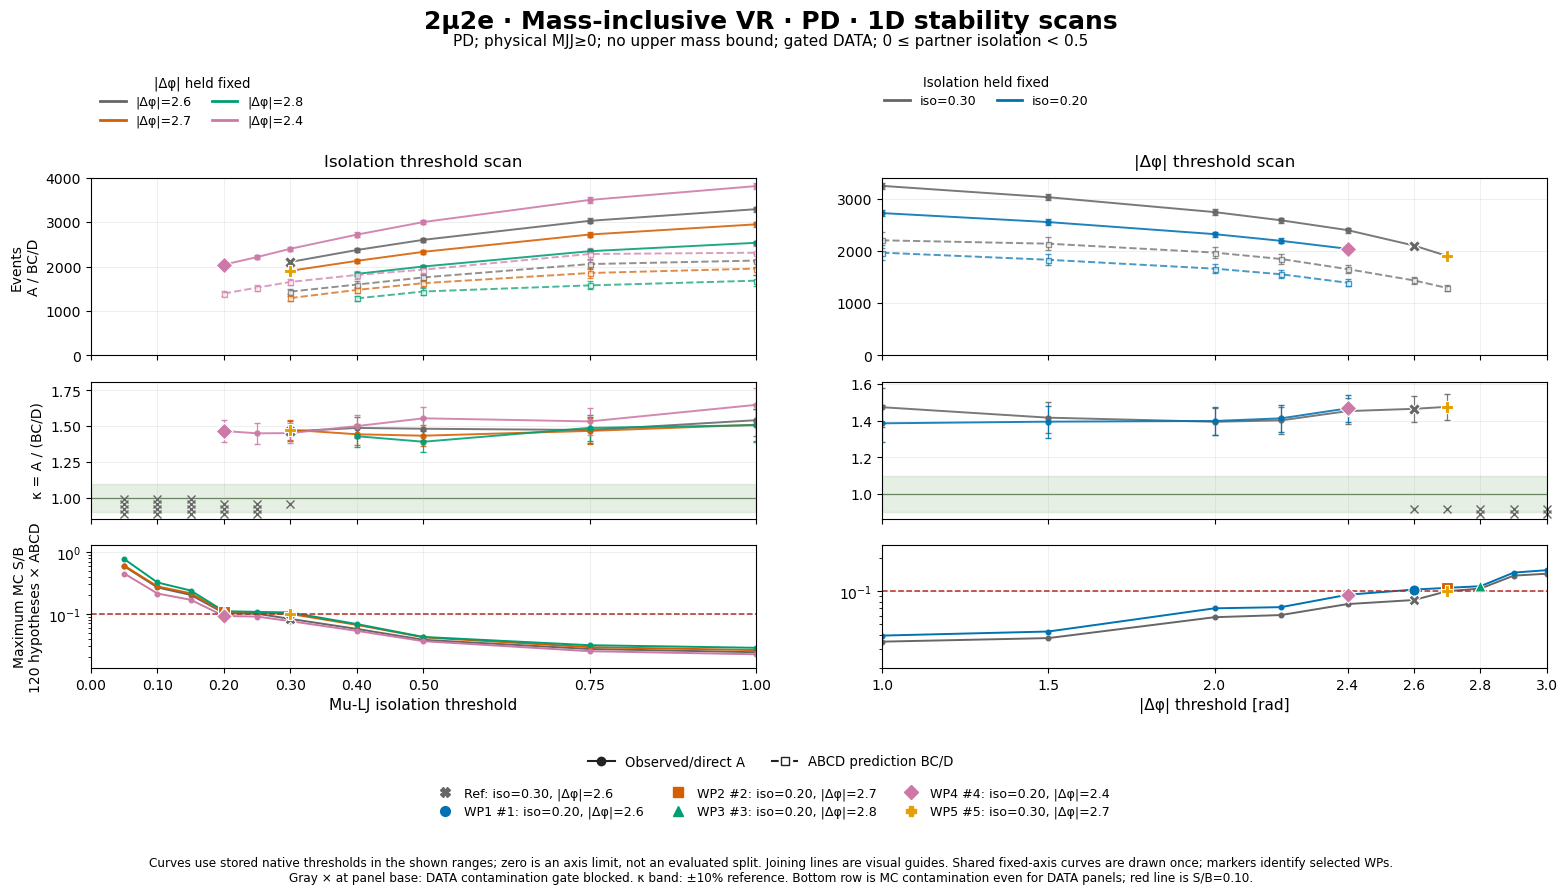

In [33]:
display(followup_lookup['mass_scan_PD'])


### V.10. All-mass DP auxiliary stability scan


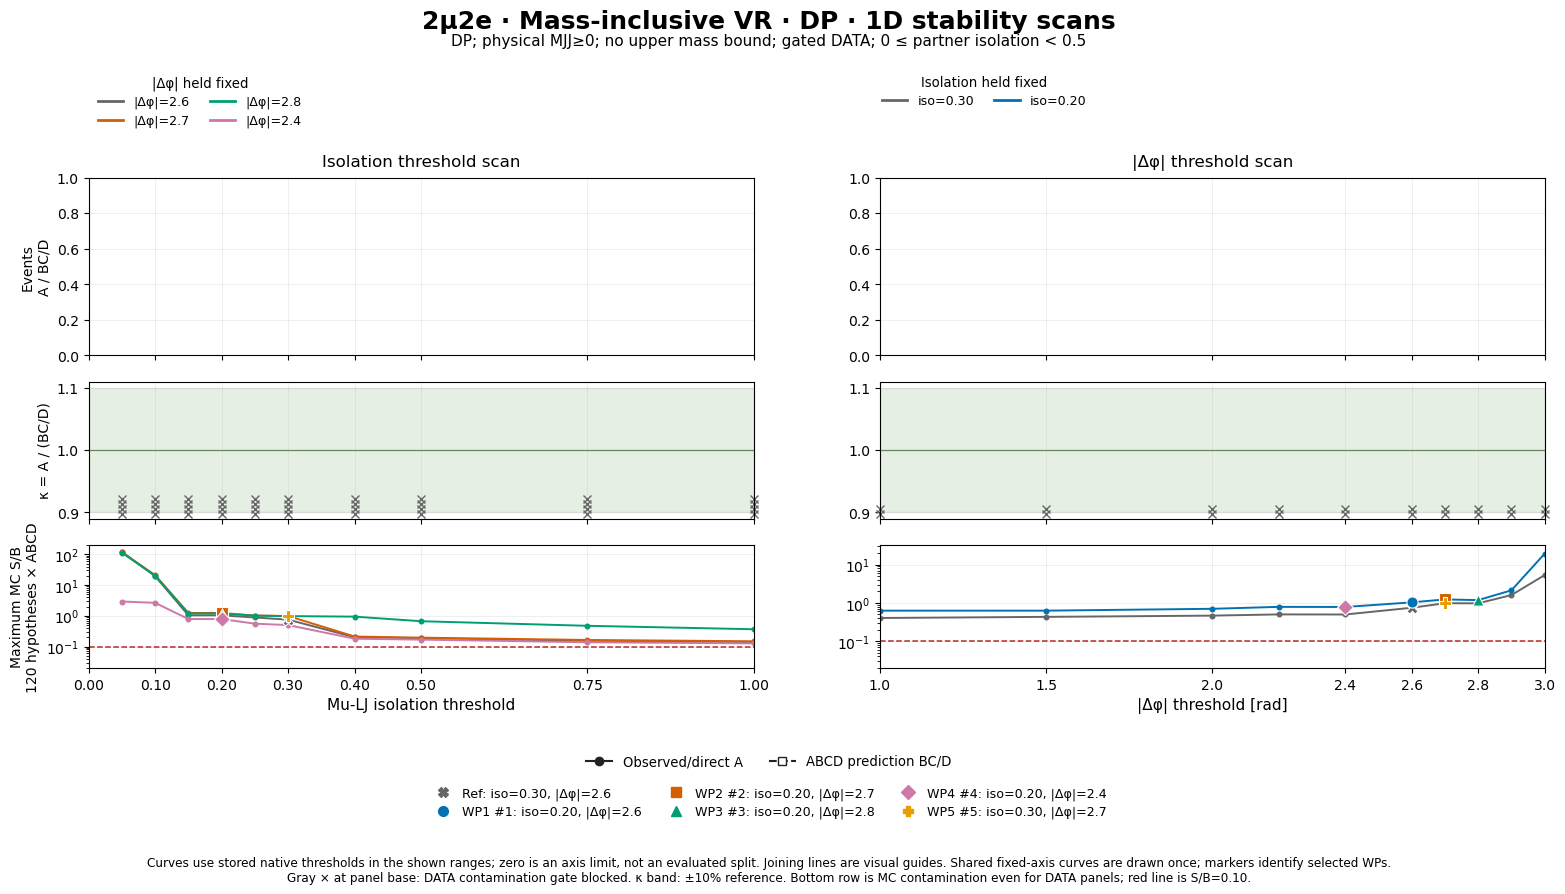

In [34]:
display(followup_lookup['mass_scan_DP'])


### V.11. Follow-up readout at the two leading candidates

The values below are generated from the same tables as the plots. For the current inputs, the low-mass addition does not dominate A at the tighter-isolation candidates, and adding the high-mass range increases contamination. WP1/WP2 all-mass DATA remain hidden by the integrated gate. The approved reference PP/PD DATA also show a closure offset.

Nominal MC suppression supports studying the tighter isolation, but its sparse effective counts and poor central closure require further investigation. Neither this inclusive VR nor the intermediate-mass VR supplies a validated nominal-DD correction. These follow-ups preserve the original MC ranking and do not establish a final WP decision from DATA.


In [35]:
from IPython.display import Markdown

nominal = followup_tables['nominal_summary'].set_index('wp')
sidebands = followup_tables['nominal_bcd_audit']
all_mass = mass_tables['selected_closure']
components = mass_tables['mass_components']
lines = []
for wp in ['WP1', 'WP2']:
    row = nominal.loc[wp]
    c_purity = sidebands.loc[sidebands.wp.eq(wp) & sidebands.region.eq('C'), 'max_S_B'].iloc[0]
    mc = all_mass.loc[all_mass.wp.eq(wp) & all_mass.source.eq('MC')].set_index('plane')
    low = components.loc[components.wp.eq(wp) & components.region.eq('A')
                         & components.mass_slice.eq('low')].set_index('plane')
    lines.append(
        f"- **{wp}:** nominal A retains {row.signal_retention_median:.1%} of the median matching-model signal "
        f"and {row.background_retention:.1%} of the background relative to the reference, "
        f"but has MC N_eff={row.neff_A:.2f} and κ={row.kappa:.3f}±{row.kappa_error:.3f}. "
        f"Nominal C max S/B={c_purity:.1%}; no nominal DATA estimate is evaluated. "
        f"All-mass max S/B: PP {mc.loc['PP', 'max_S_B']:.2%}, PD {mc.loc['PD', 'max_S_B']:.2%}, "
        f"DP {mc.loc['DP', 'max_S_B']:.2%}. "
        f"Low-mass background fractions in A: PP {low.loc['PP', 'background_fraction']:.1%}, "
        f"PD {low.loc['PD', 'background_fraction']:.1%}.")
reference_data = all_mass.loc[all_mass.wp.eq('Reference') & all_mass.source.eq('DATA')]
for row in reference_data.loc[reference_data.approved].itertuples():
    lines.append(f"- **All-mass reference {row.plane}:** DATA κ={row.kappa:.3f}±{row.kappa_error:.3f}; "
                 "compare this directly with the intermediate-mass result and retain their statistical overlap.")
display(Markdown("\n\n".join(lines)))


- **WP1:** nominal A retains 99.6% of the median matching-model signal and 9.1% of the background relative to the reference, but has MC N_eff=3.88 and κ=0.064±0.074. Nominal C max S/B=21.8%; no nominal DATA estimate is evaluated. All-mass max S/B: PP 13.74%, PD 10.33%, DP 103.51%. Low-mass background fractions in A: PP 4.5%, PD 11.2%.

- **WP2:** nominal A retains 97.2% of the median matching-model signal and 8.7% of the background relative to the reference, but has MC N_eff=3.56 and κ=0.074±0.088. Nominal C max S/B=32.4%; no nominal DATA estimate is evaluated. All-mass max S/B: PP 13.75%, PD 10.71%, DP 123.34%. Low-mass background fractions in A: PP 4.6%, PD 10.3%.

- **All-mass reference PP:** DATA κ=1.473±0.082; compare this directly with the intermediate-mass result and retain their statistical overlap.

- **All-mass reference PD:** DATA κ=1.464±0.071; compare this directly with the intermediate-mass result and retain their statistical overlap.

## Part VI — Combined checks, numerical tables and slides

The original block and its focused exports are retained. The comprehensive directory adds all diagnostics, the mass-inclusive gates and MC decomposition, selected contamination, input hashes, and **one 25-page vector PDF plus 25 PNG previews**. Raw DATA plane arrays are not exported.

The notebook reports measured MC/VR diagnostics and blocked nominal-DATA steps separately. It does not assign a VR-derived correction to nominal κ, open nominal DATA A, or choose a new boundary from these follow-up DATA plots.


In [36]:
with pd.option_context('display.max_columns', None):
    validation_counts = followup_tables['validation'].groupby(['check', 'passed'], dropna=False).size().rename('checks').reset_index()
    display(validation_counts)
all_figures = figures + followup_figures
all_definitions = pd.concat([figure_definitions.assign(section='Original intermediate-mass summary'),
                             followup_definitions.assign(section='Post-discussion follow-up')], ignore_index=True)
assert len(all_figures) == 25
COMPREHENSIVE_OUTPUT_DIR = export_comprehensive(comprehensive, CONFIG, all_figures, exports, all_definitions)
display(Markdown(f'[Complete 2mu2e PNG figure index]({COMPREHENSIVE_OUTPUT_DIR.name}/figure_manifest.csv)'))
display(Markdown(f'[Comprehensive numerical tables and previews]({COMPREHENSIVE_OUTPUT_DIR.name}/)'))


,check,passed,checks
0,Complete 154-WP DATA gating and exact displaye...,True,3
1,Intermediate mass raw MC: 154 background WPs a...,True,3
2,Nominal background and 120 signals reproduce t...,True,6
3,Only explicit PP/PD/DP all-mass projections; n...,True,1
4,Selected ABCD sumw/sumw2 equals the sum of low...,True,1
5,Three mass slices partition all physical mass ...,True,414


Comprehensive outputs: /home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_finalize/07_2mu2e_comprehensive_outputs


[Complete 2mu2e PNG figure index](07_2mu2e_comprehensive_outputs/figure_manifest.csv)

[Comprehensive numerical tables and previews](07_2mu2e_comprehensive_outputs/)